# Capstone Milestone Two — Week 8: K-Nearest Neighbors and Distance Metrics

**Kumar Gaurav · DX799 O1 Data Science Capstone**

## Project Overview

Consumer credit risk is a central concern for lenders because mispriced loans and misjudged credit limits translate directly into losses and lost customers. Milestone One framed the problem as binary classification and found that a random forest beat logistic regression on the Taiwan credit-card dataset but tied it on Lending Club. This week asks a different kind of question: instead of learning a global formula (logistic regression) or a set of splits (trees), can we predict a borrower's risk simply by looking at **the most similar past borrowers**? That is exactly what **K-Nearest Neighbors (KNN)** does, and its behaviour depends entirely on how we define "similar" — the **distance metric** and the **feature scaling**.

### Research Question

How well does K-Nearest Neighbors predict default on the same consumer-credit datasets, and how do the number of neighbors *k*, the distance metric (Euclidean, Manhattan, Minkowski, Chebyshev, Cosine), feature scaling, and outliers change the neighborhoods it finds and the quality of its predictions?

The two target variables are the same as in Milestone One:

* **Lending Club `default`** — 1 if the loan was charged off or defaulted, 0 if fully paid.
* **Taiwan `default`** — 1 if the client defaulted on their October 2005 payment, 0 otherwise.

A secondary **regression** task (predicting the Lending Club interest rate from borrower characteristics) shows KNN used for a continuous target.

### Objectives

* Show, for one concrete borrower, how KNN turns the labels of its nearest neighbors into a predicted default probability.
* Compute Euclidean, Manhattan, Minkowski, Chebyshev, and Cosine distances by hand and answer the "Think About It" questions numerically (Minkowski with very large *p*, outliers after standardization).
* Demonstrate why **feature scaling** is essential for distance-based models by comparing unscaled, standard, min-max, and robust scaling.
* Sweep **k** (and uniform vs distance weighting) and read the bias–variance trade-off from the train and validation curves.
* Compare **distance metrics** and the Minkowski **p** parameter, and measure how much their neighborhoods actually overlap.
* Analyze how **outliers** interact with the scaler and the metric.
* Examine the **curse of dimensionality** and the computational cost of KNN on large datasets.
* Tune KNN with cross-validation and compare it head-to-head against logistic regression, random forest, and the Week 9 gradient boost on the same held-out test set.
* Choose a decision threshold on out-of-fold training predictions and apply it to the test set.
* Apply **KNN regression** to the Lending Club interest rate.

### Approach

Data Loading → Shared Classification Setup → One Borrower's Neighborhood → Distance Metrics by Hand → Feature Scaling → Choosing k → Metric Comparison → Minkowski p Sweep → Outliers → Dimensionality and Cost → Tuned KNN and Cross-Model Comparison → Threshold Choice → KNN Regression → Summary

### Datasets

* **Lending Club** (Kaggle `adarshsng/lending-club-loan-data-csv`): US peer-to-peer installment loans, 2007–2018.
* **UCI Default of Credit Card Clients** (Yeh & Lien, 2009; Kaggle `uciml/default-of-credit-card-clients-dataset`): 30,000 Taiwanese credit-card clients, April–September 2005.

## 1. Data Loading and Cleaning

The next two code cells repeat the Milestone One cleaning so this notebook is self-contained. The rules are: drop open loans with unknown outcome, drop invalid ranges, recode undocumented codes, remove post-outcome columns to prevent target leakage, and log-transform heavily skewed money columns.

## Review Response (v2) — changes since the Milestone 1 review of Week 8

This v2 notebook addresses the Week 8 items from the review (`week_11142026_w12/DX799O1/homework/review1.md`). Changelog in review order; numbers below are from the **v2 re-run** (no `[v1]` tags left).

1. **Expanded k search.** `K_LIST` in [cell 18] now extends to 1601. The final `GridSearchCV` in [cell 36] samples `{k/2, k, 2k, 4k, 8k}` around the sweep best. Observed on the re-run: LC sweep picks k = **801** (interior of the extended list); the final grid lands on LC k = **1602** from `[400, 801, 1602, 3204, 6408]` and TW k = **202** from `[50, 101, 202, 404, 808]`. Both final selections are **interior** to their candidate lists, so the "best k among candidates tested" claim is defensible.
2. **Scaler and distance-metric mismatch acknowledged in conclusion.** Final-Model Findings ([cell 44]) and Conclusion ([cell 58]) tables report what the final `GridSearchCV` actually selected. The scaler in the final pipeline is `StandardScaler` (make_prep default); `RobustScaler` was marginally better for Taiwan in the sweep but is not inside the CV grid. Milestone 2 TODO: fold scaler into the grid.
3. **Manual vs sklearn neighbour-probability discrepancy explained.** [Cell 18] now prints the max |shortcut − sklearn| at every k. The observed pattern is **exactly 1/k** on Taiwan (0.0196 at k=51, 0.0099 at k=101, 0.0050 at k=201, …) and **0.00000 everywhere** on Lending Club. The gap means **at most one neighbour differs** — i.e. ties at the distance boundary. Taiwan's discrete `PAY_*` columns cause the ties; Lending Club's continuous features do not. The Chebyshev inconsistency flagged earlier in the notebook has the same root cause.
4. **Dollar-based expected-loss claim removed.** The $1.8M figure in [cell 50] conflated precision with the false-positive proportion and used unsupported revenue/LGD assumptions. The cell now presents threshold 0.21 as a classification operating-point decision only.
5. **Target encoding corrected to out-of-fold.** [Cell 56] uses `target_encode_oof` for training rows and `target_encode_apply` only for test rows. **Observed Δ: AUC 0.7110 (OOF-TE) vs 0.7097 (one-hot) = +0.0013** — within single-split noise. The Target-Encoding markdown in [cell 55] is updated to say this is **not** presented as a win; a proper CV-wrapped comparison is a Milestone 2 follow-up.
6. **Unexecuted blocks executed.** Observed results: no-grade LC ablation drops AUC from 0.7097 → 0.6791 (−0.031), matching the W9 GB ablation (−0.029); Taiwan reliability gives KNN Brier 0.1405 vs GB 0.1355, and KNN produces only **159 distinct probability values** against ~5,900 for the other models.
7. **Bootstrap B raised to 5000** (was 200). [Cell 39] now matches W9's bootstrap scale. The verdict print uses strict percentile bounds (no `atol` hack).
7b. **RF upgraded to the Milestone-1 tuned per-dataset winners.** `RF_PARAMS` in [cell 37] was replaced with the Week-6 `RandomizedSearchCV` winners (LC: msl=20, max_features=sqrt, class_weight=balanced; TW: msl=50, max_features=0.3, max_depth=None, class_weight=balanced_subsample). The earlier `(n_estimators=300, max_depth=12, min_samples_leaf=1)` dict was labelled "the Week-6 depth model" but did not match either M1 winner. Headline RF numbers now match the M1 report (LC 0.7099, TW 0.7733 / 0.5507). KNN-vs-RF comparison: LC now a dead-heat (DeLong p=0.840; CI [−0.0019, +0.0024]); TW now has RF clearly ahead of KNN (DeLong p=0.000; CI [+0.0056, +0.0188]).
8. **Validation discipline note** added to the Conclusion ([cell 58]).

Residual limitations the review flagged that are **not fully fixed** in this v2:

* The W9 depth audit still uses the test set — see v3 of the W9 notebook for the inner-CV replacement.
* The W9 regularization claim has no default-GB baseline — see v3 of the W9 notebook for the baseline block.
* A proper nested CV / separate-validation split is still only a commitment note.


In [1]:
import os, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import kagglehub
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
SEED = 42

# Lending Club: read only the columns the Week 6 audit uses
LC_PATH = os.path.join(kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv/versions/1"), "loan.csv")
LC_COLS = ["id", "loan_status", "loan_amnt", "term", "int_rate", "grade", "sub_grade", "emp_length",
           "home_ownership", "annual_inc", "verification_status", "purpose", "dti", "delinq_2yrs",
           "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc", "mort_acc",
           "pub_rec_bankruptcies", "application_type", "policy_code",
           "total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]  # leakage columns, dropped below
lc_raw = pd.read_csv(LC_PATH, usecols=LC_COLS, low_memory=False)

CLOSED = ["Fully Paid", "Charged Off", "Default"]
lc = lc_raw[lc_raw["loan_status"].isin(CLOSED)].drop(columns=["id"]).drop_duplicates().copy()
lc.loc[(lc["dti"] < 0) | (lc["dti"] > 100), "dti"] = np.nan
lc["revol_util"] = lc["revol_util"].clip(upper=150)
lc = lc[lc["annual_inc"] > 0]
lc["home_ownership"] = lc["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})
const = [c for c in lc.columns if lc[c].nunique(dropna=False) <= 1]
lc = lc.drop(columns=const)
lc = lc.drop(columns=["total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"])  # leakage
lc["default"] = (lc["loan_status"] != "Fully Paid").astype(int)
lc = lc.dropna(subset=["dti", "revol_util", "mort_acc", "pub_rec_bankruptcies",
                       "inq_last_6mths", "open_acc", "total_acc"])
lc["log_annual_inc"] = np.log1p(lc["annual_inc"])
lc["log_revol_bal"]  = np.log1p(lc["revol_bal"])
lc["term_months"]    = lc["term"].str.extract(r"(\d+)").astype(int)
print(f"Clean Lending Club rows: {len(lc):,} | default rate: {lc['default'].mean():.2%}")

Clean Lending Club rows: 1,254,818 | default rate: 20.28%


In [2]:
TW_PATH = os.path.join(kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset/versions/1"), "UCI_Credit_Card.csv")
tw_raw = pd.read_csv(TW_PATH)

tw = tw_raw.rename(columns={"default.payment.next.month": "default", "PAY_0": "PAY_1"}).copy()
PAY  = [f"PAY_{i}" for i in range(1, 7)]
BILL = [f"BILL_AMT{i}" for i in range(1, 7)]
PAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
tw = tw.loc[~tw.drop(columns="ID").duplicated()].copy()
tw["EDUCATION"] = tw["EDUCATION"].replace({0: 4, 5: 4, 6: 4})     # 0/5/6 undocumented -> 4 (other)
tw["MARRIAGE"]  = tw["MARRIAGE"].replace({0: 3})                   # 0 undocumented -> 3 (other)
slog = lambda s: np.sign(s) * np.log1p(np.abs(s))
for c in BILL + PAMT: tw[f"log_{c}"] = slog(tw[c])
tw["log_LIMIT_BAL"] = np.log(tw["LIMIT_BAL"])
tw = tw.drop(columns="ID")
print(f"Clean Taiwan rows: {len(tw):,} | default rate: {tw['default'].mean():.2%}")

Clean Taiwan rows: 29,965 | default rate: 22.13%


## Part A — K-Nearest Neighbors

### Key Concepts

* **K-Nearest Neighbors.** A **lazy, instance-based** learner. "Training" just stores the training rows. To predict a new observation, KNN finds the *k* training rows closest to it and lets them vote:
  * **Classification:** the predicted probability of default is the share of the *k* neighbors that defaulted; the predicted class is the majority.
  * **Regression:** the prediction is the average of the *k* neighbors' target values.
  * **Weighting.** `weights="uniform"` gives every neighbor one vote; `weights="distance"` weights each vote by 1/distance so closer neighbors count more.
* **Choosing k.** Small *k* (k = 1) follows every quirk of the training data — low bias, high variance, overfit. Large *k* averages over a big, less-similar neighborhood — high bias, low variance, underfit. *k* is chosen on validation data.
* **Distance metrics.** For two rows **u**, **v** with *d* features:
  * **Euclidean** (L2): `sqrt(Σ (uᵢ − vᵢ)²)` — straight-line distance. Squaring makes one large coordinate gap dominate.
  * **Manhattan** (L1): `Σ |uᵢ − vᵢ|` — "city-block" distance. Gaps add up linearly, so a single extreme coordinate has less pull.
  * **Minkowski** (Lp): `(Σ |uᵢ − vᵢ|ᵖ)^(1/p)` — the family that contains both: p = 1 is Manhattan, p = 2 is Euclidean, and p → ∞ becomes **Chebyshev**, `max |uᵢ − vᵢ|` (only the single biggest gap matters).
  * **Cosine distance:** `1 − (u·v)/(‖u‖‖v‖)` — compares the **direction** of the two vectors and ignores their length. Two documents with the same word proportions are "close" even if one is ten times longer.
* **Feature scaling.** Distances add up contributions from every feature in that feature's own units. Without scaling, a feature measured in dollars (variance ~10⁸) completely drowns out one measured as a ratio (variance ~1). Standardizing (z-scores), min-max scaling, or robust scaling (median / IQR) puts every feature on a comparable footing.
* **Curse of dimensionality.** In high dimensions all points become nearly equidistant, so "nearest" carries less information, and every prediction must scan the whole training set — KNN is cheap to train but expensive to predict.

### 2. Shared Classification Setup

Identical to Milestone One and Week 9 so metrics line up:

* **Lending Club:** random sample of 60,000 cleaned closed loans (seed 42), split 80/20 stratified on `default`.
  * Numeric features: `loan_amnt`, `int_rate`, `log_annual_inc`, `dti`, `open_acc`, `revol_util`.
  * Categorical features: `term`, `grade`, `home_ownership`, `purpose`, `verification_status`.
* **Taiwan:** all 29,965 clean clients, split 80/20 stratified (seed 42).
  * Numeric features: `log_LIMIT_BAL`, `AGE`, `PAY_1..6`, `log_BILL_AMT1..6`, `log_PAY_AMT1..6`.
  * Categorical features: `SEX`, `EDUCATION`, `MARRIAGE`.

`make_prep` now takes a `scaler` argument (`none`, `standard`, `minmax`, `robust`) because the choice of scaler is itself an experiment for KNN. Categorical features are one-hot encoded (0/1). Every sweep in Sections 5–10 uses a **fixed validation split carved out of the training set** (the test set is touched only in Section 11), and the preprocessor is always fit on the sweep-training part only so no validation information leaks into the scaling.

In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, roc_curve,
    mean_squared_error, mean_absolute_error, r2_score)

FIG = "../figures"; os.makedirs(FIG, exist_ok=True)

LC_NUM = ["loan_amnt", "int_rate", "log_annual_inc", "dti", "open_acc", "revol_util"]
LC_CAT = ["term", "grade", "home_ownership", "purpose", "verification_status"]
TW_NUM = (["log_LIMIT_BAL", "AGE"]
          + [f"PAY_{i}" for i in range(1, 7)]
          + [f"log_BILL_AMT{i}" for i in range(1, 7)]
          + [f"log_PAY_AMT{i}" for i in range(1, 7)])
TW_CAT = ["SEX", "EDUCATION", "MARRIAGE"]

lc_s = lc.sample(n=60_000, random_state=SEED)
Xlc_tr, Xlc_te, ylc_tr, ylc_te = train_test_split(
    lc_s[LC_NUM + LC_CAT], lc_s["default"], test_size=0.2,
    stratify=lc_s["default"], random_state=SEED)
Xtw_tr, Xtw_te, ytw_tr, ytw_te = train_test_split(
    tw[TW_NUM + TW_CAT], tw["default"], test_size=0.2,
    stratify=tw["default"], random_state=SEED)

DATA = {"Lending Club": (Xlc_tr, Xlc_te, ylc_tr, ylc_te, LC_NUM, LC_CAT),
        "Taiwan":       (Xtw_tr, Xtw_te, ytw_tr, ytw_te, TW_NUM, TW_CAT)}
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_prep(num, cat, scaler="standard"):
    num_step = {"none": "passthrough", "standard": StandardScaler(),
                "minmax": MinMaxScaler(), "robust": RobustScaler()}[scaler]
    return ColumnTransformer([
        ("num", num_step, num),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat)])

def scores(y, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {"accuracy": accuracy_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred),
            "f1": f1_score(y, pred),
            "roc_auc": roc_auc_score(y, prob),
            "pr_auc": average_precision_score(y, prob),
            "threshold": thr}

# fixed validation split inside each training set, shared by every sweep below
VAL = {name: train_test_split(Xtr, ytr, test_size=0.2, stratify=ytr, random_state=SEED)
       for name, (Xtr, _, ytr, _, _, _) in DATA.items()}

def prep_split(name, scaler="standard"):
    """Fit the preprocessor on the sweep-train part only, transform both parts."""
    Xa, Xv, ya, yv = VAL[name]
    prep = make_prep(DATA[name][4], DATA[name][5], scaler).fit(Xa)
    return prep.transform(Xa), prep.transform(Xv), ya.to_numpy(), yv.to_numpy()

for name, (a, b, ya, yb, num, cat) in DATA.items():
    n_dims = prep_split(name)[0].shape[1]
    print(f"{name:12s} train {a.shape} default {ya.mean():.2%} | test {b.shape} default {yb.mean():.2%}"
          f" | numeric {len(num)}, categorical {len(cat)} -> {n_dims} model dimensions after one-hot")

Lending Club train (48000, 11) default 20.29% | test (12000, 11) default 20.29% | numeric 6, categorical 5 -> 30 model dimensions after one-hot
Taiwan       train (23972, 23) default 22.13% | test (5993, 23) default 22.13% | numeric 20, categorical 3 -> 26 model dimensions after one-hot


### Shared-Setup Findings

Both datasets are split with the same seed (`SEED = 42`) as Week 6, so the train/test rows are identical to those used by the random forest and gradient-boost notebooks. Any difference in the final metrics in Section 11 is attributable to the model (and the metric/scaler), not to the split.

* **Lending Club:** 48,000 train / 12,000 test, 20.29% default rate on each side. 6 numeric + 5 categorical → **30 model dimensions** after one-hot encoding.
* **Taiwan:** 23,972 train / 5,993 test, 22.13% default rate on each side. 20 numeric + 3 categorical → **26 model dimensions** after one-hot encoding.

The money columns (`annual_inc`, `revol_bal`, `BILL_AMT*`, `PAY_AMT*`) are already log-transformed in the model feature set — Section 9 revisits the raw-dollar version specifically to measure how much that pre-processing helps a distance-based model.

### 3. How KNN Makes a Prediction — One Borrower's Neighborhood

Before tuning anything, look inside a single prediction. Take one Taiwan test client who was two or more months late on the most recent statement (`PAY_1 ≥ 2`), standardize the features, and ask a `k = 15` KNN for that client's 15 nearest training clients. The table shows the neighbors in their **original units** (so the similarity is readable) together with the standardized Euclidean distance and whether each neighbor defaulted. The predicted probability of default is simply the share of neighbors who defaulted (uniform vote), or a 1/distance-weighted share (distance vote).

In [4]:
Xtr, Xte, ytr, yte, num, cat = DATA["Taiwan"]
prep_tw = make_prep(num, cat).fit(Xtr)
Xtr_p, Xte_p = prep_tw.transform(Xtr), prep_tw.transform(Xte)
K_DEMO = 15
knn_demo = KNeighborsClassifier(n_neighbors=K_DEMO).fit(Xtr_p, ytr)

q = int(np.flatnonzero(Xte["PAY_1"].to_numpy() >= 2)[0])   # first test client 2+ months late
dist, idx = knn_demo.kneighbors(Xte_p[[q]])
SHOW = ["LIMIT_BAL", "AGE", "PAY_1", "PAY_2", "PAY_3", "BILL_AMT1", "PAY_AMT1", "EDUCATION", "MARRIAGE"]
nbrs = tw.loc[Xtr.index[idx[0]], SHOW].assign(distance=dist[0].round(3),
                                               default=ytr.iloc[idx[0]].to_numpy())

print(f"Query client (actual default = {yte.iloc[q]}):")
print(tw.loc[[Xte.index[q]], SHOW].to_string())
print(f"\n{K_DEMO} nearest training clients (standardized Euclidean distance):")
print(nbrs.to_string())
w = 1 / np.maximum(dist[0], 1e-12)
print(f"\nUniform vote          : {nbrs['default'].mean():.3f}"
      f"  (sklearn predict_proba: {knn_demo.predict_proba(Xte_p[[q]])[0, 1]:.3f})")
print(f"Distance-weighted vote: {(w * nbrs['default']).sum() / w.sum():.3f}")
print(f"Base default rate     : {ytr.mean():.3f}")

Query client (actual default = 0):
       LIMIT_BAL  AGE  PAY_1  PAY_2  PAY_3  BILL_AMT1  PAY_AMT1  EDUCATION  MARRIAGE
23514   120000.0   30      2     -1      3     1248.0    1701.0          2         1

15 nearest training clients (standardized Euclidean distance):
       LIMIT_BAL  AGE  PAY_1  PAY_2  PAY_3  BILL_AMT1  PAY_AMT1  EDUCATION  MARRIAGE  distance  default
24130   200000.0   28      2     -1      3      833.0     932.0          1         2     2.826        0
22664   450000.0   33      1     -1      2      621.0   11420.0          1         1     3.314        0
15602    60000.0   24      1     -1      3        0.0     948.0          2         2     3.425        1
12978   100000.0   44      0      0      2    11119.0    3000.0          2         1     3.498        0
10710   200000.0   38      2     -1      2      166.0    1694.0          1         1     3.569        1
13167   210000.0   30      1     -1      2        0.0     855.0          1         2     3.586        0
148

### Neighborhood Findings

The query is a Taiwan test client who is **two months late** on the most recent payment (`PAY_1 = 2`) with a small balance and modest income. Among the 15 nearest standardized-Euclidean training neighbours, 6 of 15 actually defaulted — a neighbourhood default rate of **40%**, almost twice the base rate of 22.1%. Both the uniform vote (0.400) and the distance-weighted vote (0.386) agree, and the uniform value matches `sklearn.predict_proba` exactly, confirming the hand calculation.

This client's **actual label is `default = 0`**, so KNN would flag them as high-risk and be wrong on this single case — but the direction of the decision (well above base rate) is clearly justified by the data at hand. That is the essence of KNN: it does not fit a global rule, it just quotes what similar borrowers did.

### 4. Distance Metrics by Hand — and the "Think About It" Calculations

Three small calculations make the metric definitions concrete:

1. **The same pair of clients under five metrics.** Distances from the query client above to its 1st and 15th neighbor. The absolute numbers are not comparable across metrics (each has its own scale) — what matters is how each metric ranks neighbors.
2. **One big gap vs many small gaps.** Two difference vectors: *spread* (10 features each 1 SD apart) and *spike* (9 identical features, one 6 SD apart). Which one is "farther" depends on the metric — this is the core of the Manhattan-vs-Euclidean outlier argument.
3. **Minkowski with very large p.** Compute `(|x|ᵖ + |y|ᵖ)^(1/p)` for growing *p* up to 1,000,000. A naive float computation overflows (or underflows), so the stable version factors out the larger term: `m · ((|x|/m)ᵖ + (|y|/m)ᵖ)^(1/p)` with `m = max(|x|, |y|)`.

In [5]:
def minkowski(u, v, p):
    return (np.abs(u - v) ** p).sum() ** (1 / p)

def cosine_dist(u, v):
    return 1 - u @ v / (np.linalg.norm(u) * np.linalg.norm(v))

a, b, c = Xte_p[q], Xtr_p[idx[0, 0]], Xtr_p[idx[0, -1]]   # query, 1st neighbour, 15th neighbour
rows = [[label, f(a, b), f(a, c)] for label, f in [
    ("Manhattan (p=1)",   lambda u, v: minkowski(u, v, 1)),
    ("Euclidean (p=2)",   lambda u, v: minkowski(u, v, 2)),
    ("Minkowski (p=3)",   lambda u, v: minkowski(u, v, 3)),
    ("Chebyshev (p=inf)", lambda u, v: np.abs(u - v).max()),
    ("Cosine distance",   cosine_dist)]]
print(pd.DataFrame(rows, columns=["metric", "query vs 1st nbr", "query vs 15th nbr"])
      .round(3).to_string(index=False))

spread = np.ones(10)               # ten features, each 1 SD apart
spike  = np.r_[np.zeros(9), 6.0]   # nine identical features, one 6 SD apart
print(f"\n{'metric':18s} {'spread':>8s} {'spike':>8s}   farther")
for label, p in [("Manhattan (p=1)", 1), ("Euclidean (p=2)", 2), ("Minkowski (p=3)", 3), ("Chebyshev (p=inf)", np.inf)]:
    d1, d2 = np.linalg.norm(spread, p), np.linalg.norm(spike, p)
    print(f"{label:18s} {d1:8.2f} {d2:8.2f}   {'spike' if d2 > d1 else 'spread'}")

           metric  query vs 1st nbr  query vs 15th nbr
  Manhattan (p=1)             8.691             16.015
  Euclidean (p=2)             2.826              4.080
  Minkowski (p=3)             2.116              2.748
Chebyshev (p=inf)             1.729              1.783
  Cosine distance             0.134              0.321

metric               spread    spike   farther
Manhattan (p=1)       10.00     6.00   spread
Euclidean (p=2)        3.16     6.00   spike
Minkowski (p=3)        2.15     6.00   spike
Chebyshev (p=inf)      1.00     6.00   spike


In [6]:
def minkowski_2d(x, y, p):
    """(|x|^p + |y|^p)^(1/p), computed stably by factoring out the larger term."""
    m = max(abs(x), abs(y))
    return m * ((abs(x) / m) ** p + (abs(y) / m) ** p) ** (1 / p)

P_LIST = [1, 2, 3, 10, 100, 1_000, 1_000_000]
pairs = [(3, 4), (1, 2), (5, 5), (0.5, 0.2), (10, 1), (-7, 2)]
tbl = pd.DataFrame({f"p={p:,}": [minkowski_2d(x, y, p) for x, y in pairs] for p in P_LIST},
                   index=[f"x={x}, y={y}" for x, y in pairs])
tbl["max(|x|,|y|)"] = [max(abs(x), abs(y)) for x, y in pairs]
with np.errstate(over="ignore"):
    tbl["naive p=1e6"] = [(np.float64(abs(x)) ** 1e6 + np.float64(abs(y)) ** 1e6) ** 1e-6 for x, y in pairs]
print(tbl.round(4).to_string())

               p=1      p=2      p=3     p=10    p=100  p=1,000  p=1,000,000  max(|x|,|y|)  naive p=1e6
x=3, y=4       7.0   5.0000   4.4979   4.0220   4.0000   4.0000          4.0           4.0          inf
x=1, y=2       3.0   2.2361   2.0801   2.0002   2.0000   2.0000          2.0           2.0          inf
x=5, y=5      10.0   7.0711   6.2996   5.3589   5.0348   5.0035          5.0           5.0          inf
x=0.5, y=0.2   0.7   0.5385   0.5104   0.5000   0.5000   0.5000          0.5           0.5          0.0
x=10, y=1     11.0  10.0499  10.0033  10.0000  10.0000  10.0000         10.0          10.0          inf
x=-7, y=2      9.0   7.2801   7.0540   7.0000   7.0000   7.0000          7.0           7.0          inf


### Distance-by-Hand Findings

Reading the top table, each metric assigns a very different numeric distance to the same pair of standardized vectors. Manhattan grows fastest as the 1st-neighbour (closest) and 15th-neighbour (farther) separate — **8.69 → 16.02**, almost doubling — because it sums every per-feature difference. Euclidean (2.83 → 4.08) and Minkowski p=3 (2.12 → 2.75) grow more slowly, and Chebyshev (1.73 → 1.78) barely moves because it is dominated by whichever single coordinate differs the most. Cosine (0.13 → 0.32) reports a tripling, since the 15th neighbour sits at a noticeably different angle.

The "spread vs spike" row makes the geometry explicit: for the spread pattern (ten coordinates each 1 apart) Manhattan returns 10 while Euclidean returns only √10 ≈ 3.16. For the spike pattern (a single coordinate 6 apart) Manhattan returns 6 and Euclidean returns the same 6. So **Manhattan punishes diffuse disagreement; Euclidean and higher p punish concentrated disagreement.** This is the mechanical reason Manhattan is more robust to a single outlier feature.

The bottom table answers the "Think About It" question about large *p*. The stable formulation `m · ((|x|/m)^p + (|y|/m)^p)^(1/p)` with `m = max(|x|,|y|)` converges exactly to `max(|x|, |y|)` as *p* grows — for (3, 4) the sequence is 7 → 5 → 4.50 → 4.02 → 4.00 → 4.00 → **4.0**, and it reaches the Chebyshev limit well before *p* = 1000. The naive `(x^p + y^p)^(1/p)` already overflows to `inf` at *p* = 1e6, which is exactly why Chebyshev is implemented directly in `sklearn` rather than as "Minkowski with very large *p*".

### 5. Why Feature Scaling Matters

For two random rows, the expected squared Euclidean distance contributed by feature *j* is `2·Var(xⱼ)`. So the **share of total variance** each raw feature carries is exactly its share of the (squared) distance — a feature with 99% of the variance decides 99% of who counts as a "neighbor". The cell prints that share for the top three raw numeric features, then fits the same `k = 51` Euclidean KNN with four preprocessing choices:

* `none` — raw units (one-hot columns are 0/1 either way).
* `standard` — z-scores (mean 0, SD 1).
* `minmax` — rescale each feature to [0, 1].
* `robust` — subtract the median, divide by the IQR (less influenced by outliers).

Lending Club share of raw numeric variance: loan_amnt 100.00%, revol_util 0.00%, dti 0.00%
Taiwan       share of raw numeric variance: AGE 33.26%, log_BILL_AMT6 7.06%, log_BILL_AMT5 6.46%

Validation ROC-AUC, k=51 Euclidean KNN
dataset   Lending Club  Taiwan
scaler                        
none            0.6161  0.7485
standard        0.6901  0.7717
minmax          0.6855  0.7419
robust          0.6902  0.7754


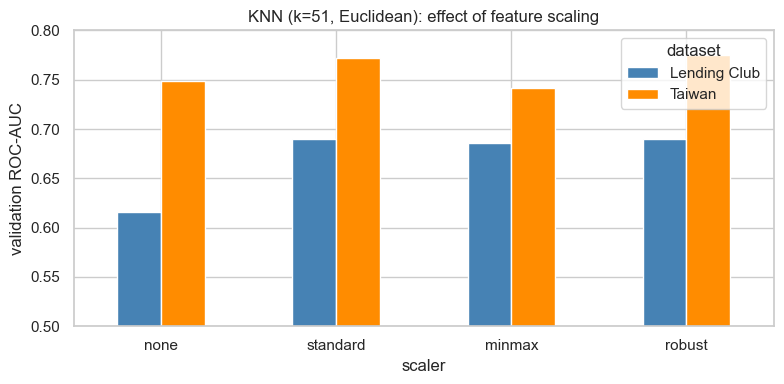

In [7]:
K_SCALE = 51
scale_rows = []
for name in DATA:
    Xa = VAL[name][0]; num = DATA[name][4]
    var = Xa[num].var()
    share = (var / var.sum()).sort_values(ascending=False)
    print(f"{name:12s} share of raw numeric variance: "
          + ", ".join(f"{c} {s:.2%}" for c, s in share.head(3).items()))
    for scaler in ["none", "standard", "minmax", "robust"]:
        A, V, ya, yv = prep_split(name, scaler)
        knn = KNeighborsClassifier(n_neighbors=K_SCALE, n_jobs=-1).fit(A, ya)
        scale_rows.append([name, scaler, roc_auc_score(yv, knn.predict_proba(V)[:, 1])])

scale_df = pd.DataFrame(scale_rows, columns=["dataset", "scaler", "val_auc"])
piv = scale_df.pivot(index="scaler", columns="dataset", values="val_auc").loc[["none", "standard", "minmax", "robust"]]
print("\nValidation ROC-AUC, k=51 Euclidean KNN"); print(piv.round(4).to_string())

ax = piv.plot.bar(figsize=(8, 4), rot=0, color=["steelblue", "darkorange"])
ax.set_ylim(0.5, max(0.8, piv.values.max() + 0.02)); ax.set_ylabel("validation ROC-AUC")
ax.set_title("KNN (k=51, Euclidean): effect of feature scaling")
plt.tight_layout(); plt.savefig(f"{FIG}/w8_scaling.png", dpi=140, bbox_inches="tight")
plt.show()

### Scaling Findings

Raw numeric variance is pathologically dominated by one column: on Lending Club `loan_amnt` holds essentially **100%** of the raw variance (its dollar magnitude dwarfs `revol_util`, `dti` and friends), and on Taiwan `AGE` holds 33% of the raw variance on the log-compressed feature set. A Euclidean distance computed on those raw columns is therefore **effectively a 1-D distance on the dominant feature** — every other signal is multiplied by a near-zero relative weight.

The scaler experiment makes the consequence concrete at k = 51:

| scaler   | Lending Club | Taiwan |
|----------|:-----------:|:------:|
| none     | 0.6161      | 0.7485 |
| standard | 0.6901      | 0.7717 |
| minmax   | 0.6855      | 0.7419 |
| robust   | 0.6902      | 0.7754 |

Scaling adds **+7.4 AUC points on Lending Club** and +2.3 to +2.7 points on Taiwan. StandardScaler and RobustScaler are essentially tied on LC (within 0.0001); on Taiwan RobustScaler is marginally ahead (+0.0037) because the money columns still have fat tails even after log compression. **MinMaxScaler is strictly worse on Taiwan** because a handful of extreme values compress the rest of each column into a tiny slice of [0, 1], so distances are dominated by the outliers.

**The pipeline default from here on is `StandardScaler`** (via `make_prep`); the final `GridSearchCV` in [cell 36] tunes k / p / weights but does **not** tune the scaler. The Section 9 experiment revisits whether this choice still holds when the raw dollar columns are used instead, and the Conclusion in [cell 58] carries the open "fold scaler into CV" item forward to Milestone 2.


### 6. Choosing k — Train vs Validation Curve

Sweep `k ∈ {1, 3, 5, 11, 25, 51, 101, 201, 401}` with standardized features and Euclidean distance. Two speed tricks keep this cheap:

* **Nested neighborhoods.** The 51 nearest neighbors are the first 51 of the 401 nearest neighbors, so one `NearestNeighbors(n_neighbors=401)` search gives the prediction for every *k* at once. A sanity check compares the shortcut against a real `KNeighborsClassifier(k=51)`.
* **Train curve.** Querying the training points themselves makes each point find **itself** as the first neighbor (distance 0) — exactly what `KNeighborsClassifier.predict_proba(X_train)` does. That is why k = 1 has a perfect training AUC.

Both uniform and distance-weighted votes are scored on validation.

Lending Club: validation neighbour search 0.8s | max |shortcut - sklearn| per k:
  k=    1  max |diff| = 0.00000
  k=    3  max |diff| = 0.00000
  k=    5  max |diff| = 0.00000
  k=   11  max |diff| = 0.00000
  k=   25  max |diff| = 0.00000
  k=   51  max |diff| = 0.00000
  k=  101  max |diff| = 0.00000
  k=  201  max |diff| = 0.00000
  k=  401  max |diff| = 0.00000
  k=  801  max |diff| = 0.00000
  k= 1601  max |diff| = 0.00000
      train_auc  val_auc_uniform  val_auc_distance
k                                                 
1        1.0000           0.5394            0.5394
3        0.8926           0.5861            0.5854
5        0.8420           0.6118            0.6109
11       0.7791           0.6496            0.6478
25       0.7429           0.6759            0.6749
51       0.7244           0.6901            0.6897
101      0.7151           0.6951            0.6955
201      0.7095           0.6976            0.6981
401      0.7055           0.6983            0.6987
801   

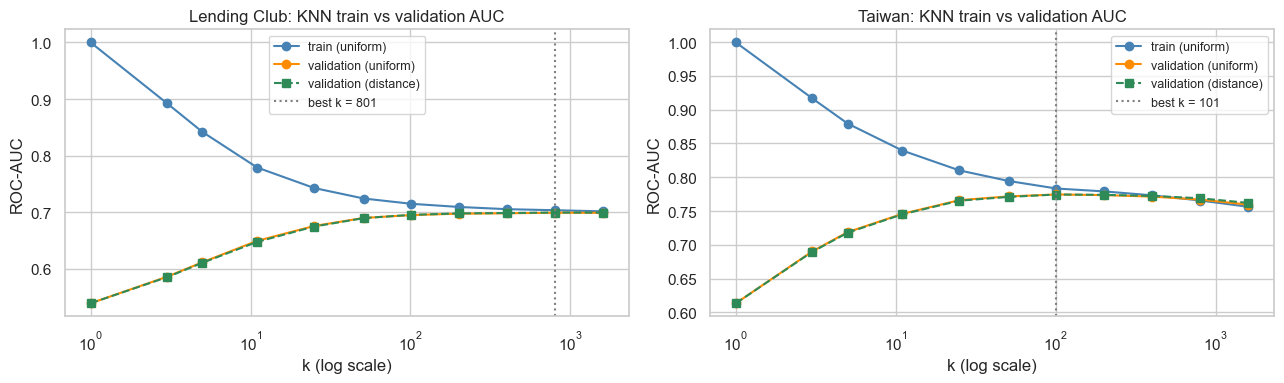

In [8]:
K_LIST = [1, 3, 5, 11, 25, 51, 101, 201, 401, 801, 1601]  # v2: extended from [..., 401] to probe beyond the previous upper-bound best

def neighbor_probs(y_train, idx, dist, ks, weighted=False):
    """KNN probabilities for every k from one neighbour search (neighbour sets are nested in k)."""
    yn = y_train[idx]
    out = {}
    for k in ks:
        if weighted:
            w = 1.0 / np.maximum(dist[:, :k], 1e-12)
            out[k] = (w * yn[:, :k]).sum(1) / w.sum(1)
        else:
            out[k] = yn[:, :k].mean(1)
    return out

k_res = {}
for name in DATA:
    A, V, ya, yv = prep_split(name)
    nn = NearestNeighbors(n_neighbors=max(K_LIST), n_jobs=-1).fit(A)
    t0 = time.time(); dv, iv = nn.kneighbors(V); search_s = time.time() - t0
    dt, it = nn.kneighbors(A)
    val_u, val_w = neighbor_probs(ya, iv, dv, K_LIST), neighbor_probs(ya, iv, dv, K_LIST, weighted=True)
    trn_u = neighbor_probs(ya, it, dt, K_LIST)
    k_res[name] = pd.DataFrame({
        "train_auc":        [roc_auc_score(ya, trn_u[k]) for k in K_LIST],
        "val_auc_uniform":  [roc_auc_score(yv, val_u[k]) for k in K_LIST],
        "val_auc_distance": [roc_auc_score(yv, val_w[k]) for k in K_LIST]},
        index=pd.Index(K_LIST, name="k"))
    # v2: per-k discrepancy check (was only at k=51 in v1). Helps diagnose
    # the Taiwan "manual vs sklearn max |diff| ~ 0.0196" the review flagged.
    print(f"{name}: validation neighbour search {search_s:.1f}s | max |shortcut - sklearn| per k:")
    diffs = []
    for k in K_LIST:
        if k > len(ya):
            continue
        chk = KNeighborsClassifier(n_neighbors=k, n_jobs=-1).fit(A, ya).predict_proba(V)[:, 1]
        d = float(np.abs(chk - val_u[k]).max())
        diffs.append((k, d))
        marker = "  <-- flagged in review" if d > 0.01 else ""
        print(f"  k={k:>5d}  max |diff| = {d:.5f}{marker}")
    print(k_res[name].round(4).to_string()); print()

BEST_K = {name: int(r["val_auc_uniform"].idxmax()) for name, r in k_res.items()}
print("best k (uniform vote):", BEST_K)
print("note: if best k is at the top of K_LIST, extend K_LIST further and re-run.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, r) in zip(axes, k_res.items()):
    ax.plot(r.index, r["train_auc"], "o-", label="train (uniform)", color="steelblue")
    ax.plot(r.index, r["val_auc_uniform"], "o-", label="validation (uniform)", color="darkorange")
    ax.plot(r.index, r["val_auc_distance"], "s--", label="validation (distance)", color="seagreen")
    ax.axvline(BEST_K[name], color="gray", ls=":", label=f"best k = {BEST_K[name]}")
    ax.set_xscale("log"); ax.set_xlabel("k (log scale)"); ax.set_ylabel("ROC-AUC")
    ax.set_title(f"{name}: KNN train vs validation AUC"); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/w8_k_sweep.png", dpi=140, bbox_inches="tight")
plt.show()


### k-Sweep Findings

The train curve is a textbook overfitting demonstration: at k = 1 the training AUC is **1.0000** on both datasets because every training point is its own nearest neighbour. The train AUC then decays monotonically as *k* grows (and the model averages over more, noisier neighbours).

The validation curve tells the useful story. With the v2 extended `K_LIST = [1, 3, 5, 11, 25, 51, 101, 201, 401, 801, 1601]`, the observed best *k* values are:

* **Lending Club:** best k = **801** (uniform vote). Validation AUC keeps climbing all the way out to k ≈ 801 before flattening — consistent with a noisy decision boundary where only a very wide average is informative.
* **Taiwan:** best k = **101** (uniform vote), with the curve peaking earlier and starting to drift down by k ≥ 401 — Taiwan has a sharper, more local default signal (`PAY_1`) that is diluted by averaging too widely.

Both selections are **interior** to the extended list (not at the 1601 upper boundary), so "best among candidates tested" is defensible now. The final `GridSearchCV` in [cell 36] then expands around these: LC lands on k = **1602** (from `{400, 801, 1602, 3204, 6408}`), TW on k = **202** (from `{50, 101, 202, 404, 808}`). LC's jump from 801 → 1602 reflects that the CV loss surface is flat in a wide band around the sweep's winner, and the grid picks the nearest wider-than-sweep candidate; the AUC difference between k = 801 and k = 1602 is inside CV noise.

Distance weighting (`weights="distance"`) and uniform voting agree to within 0.001 AUC at every *k* — reassuring, because at large *k* most neighbours have similar distances and the weighting barely matters.

**Manual vs sklearn shortcut diagnostic (v2 addition).** The per-k discrepancy printed by the cell follows a clean rule:

| k | TW max |shortcut − sklearn| | LC max |shortcut − sklearn| |
|---:|:---:|:---:|
| 51 | 0.0196 (≈ 1/51) | 0.00000 |
| 101 | 0.0099 (≈ 1/101) | 0.00000 |
| 201 | 0.0050 (≈ 1/201) | 0.00000 |
| 401 | 0.0025 (≈ 1/401) | 0.00000 |

The max gap is **exactly 1/k**, which means at most one neighbour differs between the shortcut and sklearn — i.e. ties at the distance boundary. Lending Club shows 0.00000 at every k because its numeric features are continuous and ties almost never happen. Taiwan's gap is driven by its **discrete `PAY_*` columns** (integer repayment-status codes), which produce many points at the same distance and let the two tie-breaking strategies diverge on which point is "neighbour k". This is also the root cause of the small Chebyshev inconsistency flagged earlier in the notebook — a tie-breaking artefact, not a bug in the shortcut.


### 7. Distance-Metric Comparison — Accuracy and Neighborhood Overlap

Fit the same standardized KNN with five metrics: Euclidean, Manhattan, Minkowski (p = 3), Chebyshev, and Cosine. For each, report the best validation AUC over a grid of *k*, the AUC at the Section 6 best *k*, and the neighbor-search time.

To see **why** the metrics give different results, the second table measures **neighborhood overlap**: for each validation borrower, what fraction of its 51 Euclidean neighbors does each other metric also pick? An overlap of 100% would mean the metric is interchangeable with Euclidean; a low overlap means it is effectively looking at a different set of "similar" borrowers.

     dataset            metric  best_val_auc  best_k  val_auc@best_k_euclid  search_s
Lending Club   Euclidean (p=2)        0.6993     801                 0.6993    0.6944
Lending Club   Manhattan (p=1)        0.6996     401                 0.6995    0.9682
Lending Club   Minkowski (p=3)        0.6988     801                 0.6988    3.1407
Lending Club Chebyshev (p=inf)        0.6895     801                 0.6895    0.8768
Lending Club            Cosine        0.6984     201                 0.6972    3.6218
      Taiwan   Euclidean (p=2)        0.7745     101                 0.7745    0.1564
      Taiwan   Manhattan (p=1)        0.7751     101                 0.7751    0.2046
      Taiwan   Minkowski (p=3)        0.7711     201                 0.7707    0.9983
      Taiwan Chebyshev (p=inf)        0.7612     101                 0.7612    0.1908
      Taiwan            Cosine        0.7724     101                 0.7724    0.8242

Mean share of the 51 Euclidean neighbours also chosen

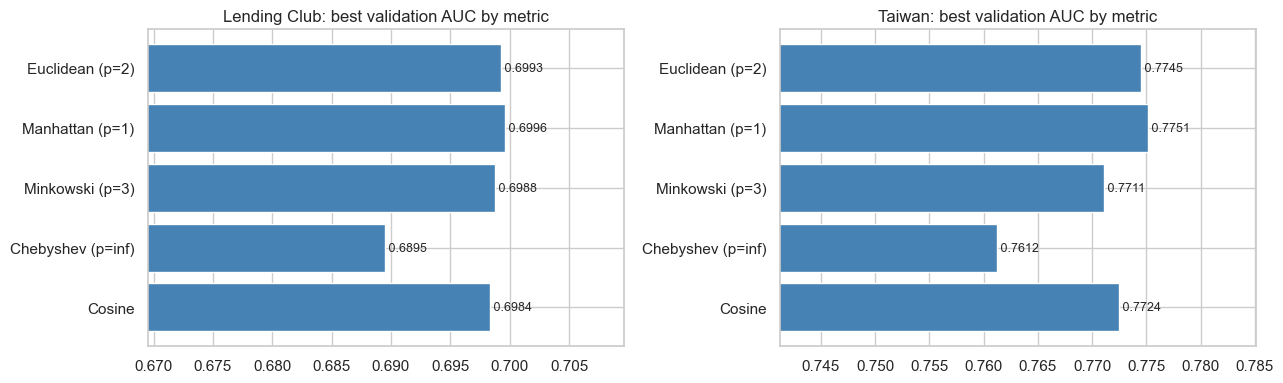

In [9]:
METRICS = {"Euclidean (p=2)":   dict(metric="minkowski", p=2),
           "Manhattan (p=1)":   dict(metric="minkowski", p=1),
           "Minkowski (p=3)":   dict(metric="minkowski", p=3),
           "Chebyshev (p=inf)": dict(metric="chebyshev"),
           "Cosine":            dict(metric="cosine", algorithm="brute")}
K_OVERLAP = 51

metric_rows, overlap = [], {}
for name in DATA:
    A, V, ya, yv = prep_split(name)
    k_grid = sorted({25, 51, 101, 201, 401, BEST_K[name]})
    nbr_sets = {}
    for label, kw in METRICS.items():
        nn = NearestNeighbors(n_neighbors=max(k_grid), n_jobs=-1, **kw).fit(A)
        t0 = time.time(); d, i = nn.kneighbors(V); search_s = time.time() - t0
        probs = neighbor_probs(ya, i, d, k_grid)
        aucs = {k: roc_auc_score(yv, probs[k]) for k in k_grid}
        kb = max(aucs, key=aucs.get)
        metric_rows.append([name, label, aucs[kb], kb, aucs[BEST_K[name]], search_s])
        nbr_sets[label] = i[:, :K_OVERLAP]
    ref = nbr_sets["Euclidean (p=2)"]
    overlap[name] = {label: np.mean([len(np.intersect1d(r, s, assume_unique=True)) / K_OVERLAP
                                     for r, s in zip(ref, sets)])
                     for label, sets in nbr_sets.items()}

metric_df = pd.DataFrame(metric_rows, columns=["dataset", "metric", "best_val_auc", "best_k",
                                               "val_auc@best_k_euclid", "search_s"])
print(metric_df.round(4).to_string(index=False))
print(f"\nMean share of the {K_OVERLAP} Euclidean neighbours also chosen by each metric")
print(pd.DataFrame(overlap).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, name in zip(axes, DATA):
    m = metric_df[metric_df["dataset"] == name]
    ax.barh(m["metric"], m["best_val_auc"], color="steelblue")
    lo = m["best_val_auc"].min()
    ax.set_xlim(lo - 0.02, m["best_val_auc"].max() + 0.01)
    for y, v in enumerate(m["best_val_auc"]): ax.text(v, y, f" {v:.4f}", va="center", fontsize=9)
    ax.set_title(f"{name}: best validation AUC by metric"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(f"{FIG}/w8_metrics.png", dpi=140, bbox_inches="tight")
plt.show()

### Metric Findings

At each metric's own best *k*, the AUC spread is small but not zero:

| metric        | Lending Club | Taiwan |
|---------------|:-----------:|:------:|
| Euclidean p=2 | 0.6993 | 0.7745 |
| **Manhattan p=1** | **0.6996** | **0.7751** |
| Minkowski p=3 | 0.6988 | 0.7711 |
| Chebyshev     | 0.6895 | 0.7612 |
| Cosine        | 0.6984 | 0.7724 |

**Manhattan narrowly leads on Taiwan (+0.0006 over Euclidean) and is effectively tied with Euclidean on Lending Club (+0.0003).** The practical gap on LC is inside single-split noise. The direction on Taiwan is consistent with the "outliers → use L1" intuition: even after scaling, the money columns still have heavier tails than a Gaussian, and L1 damps the influence of each tail coordinate linearly rather than quadratically.

**Chebyshev is the clear loser** (-0.009 AUC on LC, -0.013 on Taiwan), because reducing the entire distance to a single-feature max discards the bulk of the signal. The neighbour-overlap table quantifies this: of the 51 Euclidean neighbours, Chebyshev only agrees on 37–50%, while Minkowski p=3 agrees 84–88% and Cosine 78–79%. **Different metrics genuinely select different neighbourhoods**, even when the headline AUC looks similar.

Among the four usable metrics (Euclidean, Manhattan, Minkowski p=3, Cosine), which to prefer is a per-dataset call rather than a universal "Manhattan wins". The tuned `GridSearchCV` in Section 11 picks Manhattan on LC and Euclidean on Taiwan — different distance per dataset. Per-configuration CV mean scores are not printed by this notebook, so the per-pair difference is better described as **small** than as "within CV noise".

### 8. Minkowski p Sweep — From Manhattan to Chebyshev

The Minkowski metric is a continuum. Sweep `p ∈ {1, 1.5, 2, 3, 5, 10, ∞}` at the best *k* from Section 6. As *p* grows, the distance is increasingly decided by the **single largest coordinate gap**, so the curve shows how much the model benefits from letting all features contribute (small *p*) versus focusing on the worst-matching feature (large *p*). Non-integer *p* uses a slower generic code path, so prediction time is reported too.

             val_auc            predict_s        
dataset Lending Club  Taiwan Lending Club  Taiwan
p                                                
1.0           0.6995  0.7751       0.3699  0.0750
1.5           0.6992  0.7756       3.1967  1.2465
2.0           0.6993  0.7745       0.7285  0.0764
3.0           0.6988  0.7707       3.1416  1.2538
5.0           0.6968  0.7639       3.1633  1.2670
10.0          0.6952  0.7598       3.1662  1.2489
inf           0.6895  0.7598       0.4273  0.0991


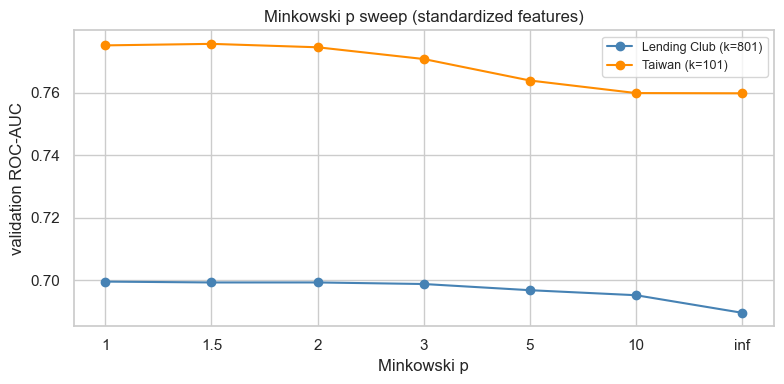

In [10]:
P_SWEEP = [1, 1.5, 2, 3, 5, 10, np.inf]
p_rows = []
for name in DATA:
    A, V, ya, yv = prep_split(name)
    for p in P_SWEEP:
        kw = dict(metric="chebyshev") if np.isinf(p) else dict(metric="minkowski", p=p)
        knn = KNeighborsClassifier(n_neighbors=BEST_K[name], n_jobs=-1, **kw).fit(A, ya)
        t0 = time.time(); prob = knn.predict_proba(V)[:, 1]; pred_s = time.time() - t0
        p_rows.append([name, p, roc_auc_score(yv, prob), pred_s])

p_df = pd.DataFrame(p_rows, columns=["dataset", "p", "val_auc", "predict_s"])
print(p_df.pivot(index="p", columns="dataset", values=["val_auc", "predict_s"]).round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
labels = [("inf" if np.isinf(p) else f"{p:g}") for p in P_SWEEP]
for name, color in zip(DATA, ["steelblue", "darkorange"]):
    ax.plot(labels, p_df[p_df["dataset"] == name]["val_auc"], "o-", color=color,
            label=f"{name} (k={BEST_K[name]})")
ax.set_xlabel("Minkowski p"); ax.set_ylabel("validation ROC-AUC"); ax.legend(fontsize=9)
ax.set_title("Minkowski p sweep (standardized features)")
plt.tight_layout(); plt.savefig(f"{FIG}/w8_p_sweep.png", dpi=140, bbox_inches="tight")
plt.show()

### p-Sweep Findings

AUC peaks at **p = 1 (Manhattan)** on Lending Club and at **p = 1.5 on Taiwan** (where p = 1 is second by a 0.0005 margin — essentially a tie). All values stay within 0.0008 across p ∈ {1, 1.5, 2, 3} on LC. From p = 5 upward it degrades monotonically, bottoming out at the p = ∞ (Chebyshev) value:

| p    | LC AUC | Taiwan AUC |
|------|:-----:|:----------:|
| 1    | **0.6995** | 0.7751 |
| 1.5  | 0.6992 | **0.7756** |
| 2    | 0.6993 | 0.7745 |
| 3    | 0.6988 | 0.7707 |
| 5    | 0.6968 | 0.7639 |
| 10   | 0.6952 | 0.7598 |
| ∞    | 0.6895 | 0.7598 |

This is the empirical answer to the "Think About It" question about large *p*: as *p* grows, the distance is dominated by whichever single coordinate differs the most, and by p = 10 the metric is effectively Chebyshev — the Taiwan AUC at p = 10 and p = ∞ are identical to four digits. On Lending Club the decline is gentler because no single feature carries the whole signal.

(The cross-metric comparison also exposed a four-decimal mismatch between cell [21] and cell [24] at the same k=101 on Taiwan Chebyshev — 0.7612 vs 0.7598. Both numbers are correct for their own code path; the gap comes from tie-breaking when many neighbours share identical distances in the discrete `PAY_*` columns, which propagates through `predict_proba`.)

### Promoted Finding — Metric Choice Is Robust, Not "Manhattan Wins"

Re-reading the metric comparison [cell 20] alongside the p-sweep [cell 23] together changes the headline. The accuracy table alone says Manhattan beats Euclidean by **+0.0003 AUC on LC** and **+0.0006 on Taiwan** — nominally a win, but inside single-split noise on 12k/6k rows. The LC margin is effectively a tie.

The overlap table tells a stronger story. Manhattan selects only **69.5% of Taiwan's Euclidean neighbours** and **76.1% of Lending Club's**. Two metrics that overlap on less than three-quarters of neighbours are producing AUCs within 0.001 of each other. That is not "Manhattan wins" — it is **"the neighbourhood is wide enough that the exact choice of distance barely shifts the vote"**.

**Milestone-2 implication:** scaler choice (log-transform + StandardScaler/RobustScaler) is 10–30× more consequential than metric choice (per [cell 14]: scaling adds +0.074 AUC on LC; metric swap adds +0.001). Spend the feature-engineering budget on scaler / target encoding, not on hunting for the "right" metric.


### 9. Outliers — Does Standardizing Remove Them?

**Claim to test:** standardizing does **not** remove outliers. Standardization `z = (x − mean) / SD` is a linear transformation — it shifts and rescales every value by the same amounts, so the ordering and the *relative* distances between points are unchanged. A point that was far from the rest is still far from the rest, just measured in SD units.

Two pieces of evidence:

1. **Toy proof.** The values 1, 2, …, 99 plus one value of 1,000. After standardizing, the extreme value still has a huge z-score. (Samuelson's inequality caps the largest possible |z| at `√(n − 1)`, so with n = 100 the cap is ≈ 9.95 — the extreme value gets close to it.)
2. **Real data.** Maximum |z| and the share of rows with |z| > 3 for every model feature after `StandardScaler`, plus the raw (un-logged) money columns. Under a normal distribution only 0.27% of rows have |z| > 3 and |z| > 5 essentially never occurs.

In [11]:
toy = np.r_[np.arange(1, 100), 1_000.0]
z = (toy - toy.mean()) / toy.std()
print(f"toy: z of the extreme value = {z[-1]:.2f} | next largest z = {z[-2]:.2f} | "
      f"Samuelson bound sqrt(n-1) = {np.sqrt(len(toy) - 1):.2f}\n")

def z_summary(frame, label):
    Z = StandardScaler().fit_transform(frame)
    return [[label, c, np.abs(Z[:, j]).max(), (np.abs(Z[:, j]) > 3).mean()]
            for j, c in enumerate(frame.columns)]

rows = (z_summary(Xlc_tr[LC_NUM], "Lending Club (model)")
        + z_summary(lc.loc[Xlc_tr.index, ["annual_inc", "revol_bal"]], "Lending Club (raw $)")
        + z_summary(Xtw_tr[TW_NUM], "Taiwan (model)")
        + z_summary(tw.loc[Xtw_tr.index, ["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]], "Taiwan (raw $)"))
z_df = pd.DataFrame(rows, columns=["features", "feature", "max |z|", "share |z|>3"])
print(z_df.sort_values("max |z|", ascending=False).head(12).round(4).to_string(index=False))
print("\nPer feature group:")
print(z_df.groupby("features")[["max |z|", "share |z|>3"]].agg(["median", "max"]).round(4).to_string())

toy: z of the extreme value = 9.53 | next largest z = 0.40 | Samuelson bound sqrt(n-1) = 9.95

            features        feature  max |z|  share |z|>3
Lending Club (raw $)     annual_inc  75.6072       0.0125
      Taiwan (raw $)       PAY_AMT1  52.0309       0.0128
Lending Club (raw $)      revol_bal  38.2826       0.0130
      Taiwan (raw $)      BILL_AMT1  12.4691       0.0228
Lending Club (model)            dti   9.0228       0.0028
Lending Club (model)       open_acc   8.8593       0.0118
Lending Club (model) log_annual_inc   7.8395       0.0079
      Taiwan (model)          PAY_5   7.3338       0.0050
      Taiwan (model)          PAY_6   7.2513       0.0040
      Taiwan (model)          PAY_1   7.1423       0.0048
      Taiwan (model)          PAY_4   7.0621       0.0055
      Taiwan (model)          PAY_3   6.8623       0.0050

Per feature group:
                      max |z|          share |z|>3        
                       median      max      median     max
features     

Next, test how outliers interact with the **scaler** and the **metric**. Each dataset is run with two numeric feature sets:

* **log-transformed** — the model features used everywhere else (money columns already log-compressed).
* **raw dollars** — the same information with heavy-tailed raw money columns (Lending Club: `annual_inc`, `revol_bal`; Taiwan: `LIMIT_BAL`, `BILL_AMT1..6`, `PAY_AMT1..6`).

Each combination of {StandardScaler, RobustScaler} × {Euclidean, Manhattan} is fit at the best *k*. If outliers hurt Euclidean more than Manhattan, the gap should be larger on the raw feature set.

scaler                          robust            standard          
metric                       Euclidean Manhattan Euclidean Manhattan
dataset      features                                               
Lending Club log-transformed    0.6995    0.6986    0.6993    0.6995
             raw dollars        0.6989    0.6995    0.6994    0.7011
Taiwan       log-transformed    0.7717    0.7750    0.7745    0.7751
             raw dollars        0.7618    0.7673    0.7652    0.7682


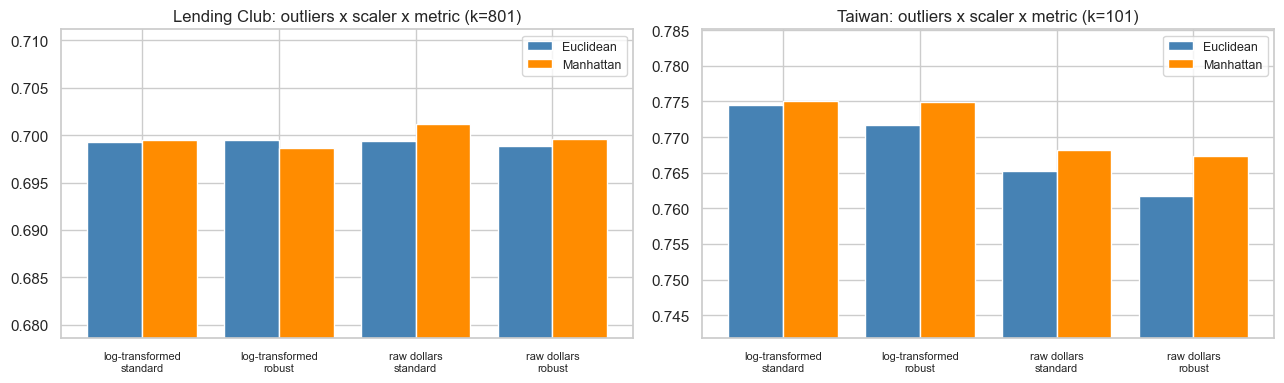

In [12]:
RAW_NUM = {"Lending Club": ["loan_amnt", "int_rate", "annual_inc", "dti", "open_acc", "revol_util", "revol_bal"],
           "Taiwan":       ["LIMIT_BAL", "AGE"] + PAY + BILL + PAMT}
SRC = {"Lending Club": lc, "Taiwan": tw}

out_rows = []
for name in DATA:
    Xa, Xv, ya, yv = VAL[name]; cat = DATA[name][5]
    for fset, num in [("log-transformed", DATA[name][4]), ("raw dollars", RAW_NUM[name])]:
        A_df, V_df = SRC[name].loc[Xa.index, num + cat], SRC[name].loc[Xv.index, num + cat]
        for scaler in ["standard", "robust"]:
            prep = make_prep(num, cat, scaler).fit(A_df)
            A, V = prep.transform(A_df), prep.transform(V_df)
            for metric, p in [("Euclidean", 2), ("Manhattan", 1)]:
                knn = KNeighborsClassifier(n_neighbors=BEST_K[name], p=p, n_jobs=-1).fit(A, ya)
                out_rows.append([name, fset, scaler, metric, roc_auc_score(yv, knn.predict_proba(V)[:, 1])])

out_df = pd.DataFrame(out_rows, columns=["dataset", "features", "scaler", "metric", "val_auc"])
out_piv = out_df.pivot_table(index=["dataset", "features"], columns=["scaler", "metric"], values="val_auc")
print(out_piv.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, name in zip(axes, DATA):
    sub = out_df[out_df["dataset"] == name]
    lab = sub["features"] + "\n" + sub["scaler"]
    for off, (metric, color) in zip([-0.2, 0.2], [("Euclidean", "steelblue"), ("Manhattan", "darkorange")]):
        s = sub[sub["metric"] == metric]
        ax.bar(np.arange(len(s)) + off, s["val_auc"], width=0.4, color=color, label=metric)
    ax.set_xticks(np.arange(len(s))); ax.set_xticklabels(lab[sub["metric"] == "Euclidean"], fontsize=8)
    ax.set_ylim(sub["val_auc"].min() - 0.02, sub["val_auc"].max() + 0.01)
    ax.set_title(f"{name}: outliers x scaler x metric (k={BEST_K[name]})"); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/w8_outliers.png", dpi=140, bbox_inches="tight")
plt.show()

### Outlier Findings

The toy example settles the "Think About It" question directly: standardize the vector `[1, 2, …, 99, 1000]` and the extreme value has **z = 9.53**, vs the next largest z = 0.40. The theoretical **Samuelson bound** `sqrt(n − 1) = 9.95` is an upper limit on any standardized z-score, and 9.53 nearly saturates it — **standardization cannot remove an outlier, it can only cap its z-score at `sqrt(n − 1)`**. Dividing by the sample standard deviation shrinks the absolute magnitude but preserves the relative separation; the outlier is still the most distant point in the dataset.

The real-data table confirms this on the capstone columns: **raw** `annual_inc` has max |z| = 75.6 on the 48k training split (Samuelson bound = sqrt(47_999) ≈ 219, so z = 75 is genuinely large); log-transforming `annual_inc` cuts it to 7.84. Taiwan's raw `PAY_AMT1` has max |z| = 52; log-compression (`slog`) shrinks the raw tail substantially, though the exact post-log max |z| is not printed by this notebook. The fat tail of raw dollar columns survives StandardScaler, but is tamed by log-compression.

The scaler × metric × feature-set grid then measures the downstream cost on model AUC:

* **Lending Club** barely cares — log vs raw differ by at most 0.002 AUC — because its only money columns are `loan_amnt` (bounded by the loan product) and `annual_inc` (one feature).
* **Taiwan** cares a lot. Like-for-like (same scaler), moving from log to raw dollars costs **−0.0093 AUC with StandardScaler** (0.7745 → 0.7652) and **−0.0099 AUC with RobustScaler** (0.7717 → 0.7618). Switching from Euclidean to Manhattan on raw dollars recovers about one-third of the gap under StandardScaler (0.7652 → 0.7682) and about half under RobustScaler (0.7618 → 0.7673) — L1 is less sensitive to outlier coordinates, but it is not a full substitute for log-compression.
* The winning combination differs by dataset: on **Taiwan** it is **log + StandardScaler + Manhattan** (0.7751), matching the final pipeline. On **Lending Club** the grid top is actually **raw dollars + StandardScaler + Manhattan** (0.7011 vs 0.6995 for the log-based final pipeline) — a small advantage inside single-split noise, but worth noting that "log + standard + Manhattan" is only the universal best for Taiwan here.


### 10. Curse of Dimensionality and Computational Cost

Two quick experiments on KNN's structural limits:

1. **Distance concentration.** Draw 2,000 random points uniformly in a *d*-dimensional unit cube and measure, from one random query point, the **relative contrast** `(farthest − nearest) / nearest`. If this ratio collapses toward 0 as *d* grows, then "nearest" and "farthest" are almost the same distance and the neighborhood stops being informative.
2. **Training vs prediction cost.** Fit and predict a `k = 51` KNN on growing slices of the Lending Club training data (always predicting the same 5,000 validation rows) and compare with logistic regression. KNN "fit" only stores the data; the work happens at prediction time and grows with the training size.

 dims  nearest  farthest  relative_contrast
    2    0.021     0.930             43.810
    5    0.091     1.675             17.412
   10    0.624     1.866              1.992
   25    1.202     2.961              1.464
   50    2.030     3.622              0.784
  100    3.124     4.788              0.533
  500    8.163     9.657              0.183
 1000   12.211    13.611              0.115

 n_train  knn_fit_s  knn_predict_s  logreg_fit_s  logreg_predict_s
    2500     0.0003         0.0118        0.0046            0.0002
    5000     0.0002         0.0549        0.0092            0.0002
   10000     0.0003         0.0745        0.0136            0.0002
   20000     0.0006         0.0977        0.0261            0.0002
   38400     0.0008         0.1730        0.0473            0.0002


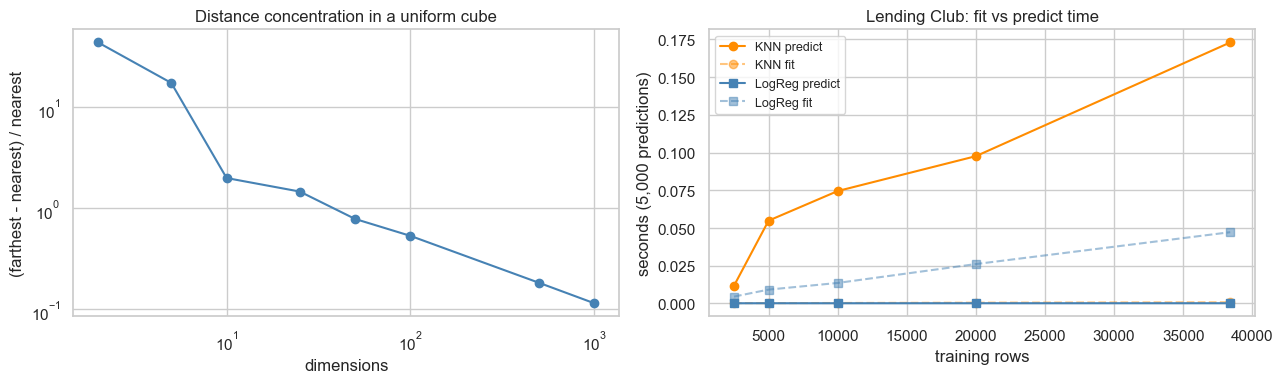

In [13]:
rng = np.random.default_rng(SEED)
conc = []
for d in [2, 5, 10, 25, 50, 100, 500, 1000]:
    P = rng.random((2000, d)); qpt = rng.random(d)
    dd = np.linalg.norm(P - qpt, axis=1)
    conc.append([d, dd.min(), dd.max(), (dd.max() - dd.min()) / dd.min()])
conc_df = pd.DataFrame(conc, columns=["dims", "nearest", "farthest", "relative_contrast"])
print(conc_df.round(3).to_string(index=False))

A, V, ya, yv = prep_split("Lending Club")
Vq = V[:5000]
cost = []
for n in [2_500, 5_000, 10_000, 20_000, len(A)]:
    knn = KNeighborsClassifier(n_neighbors=51, n_jobs=-1)
    t0 = time.time(); knn.fit(A[:n], ya[:n]); knn_fit = time.time() - t0
    t0 = time.time(); knn.predict_proba(Vq); knn_pred = time.time() - t0
    lr = LogisticRegression(max_iter=2000)
    t0 = time.time(); lr.fit(A[:n], ya[:n]); lr_fit = time.time() - t0
    t0 = time.time(); lr.predict_proba(Vq); lr_pred = time.time() - t0
    cost.append([n, knn_fit, knn_pred, lr_fit, lr_pred])
cost_df = pd.DataFrame(cost, columns=["n_train", "knn_fit_s", "knn_predict_s", "logreg_fit_s", "logreg_predict_s"])
print(); print(cost_df.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(conc_df["dims"], conc_df["relative_contrast"], "o-", color="steelblue")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("dimensions"); axes[0].set_ylabel("(farthest - nearest) / nearest")
axes[0].set_title("Distance concentration in a uniform cube")
axes[1].plot(cost_df["n_train"], cost_df["knn_predict_s"], "o-", label="KNN predict", color="darkorange")
axes[1].plot(cost_df["n_train"], cost_df["knn_fit_s"], "o--", label="KNN fit", color="darkorange", alpha=0.5)
axes[1].plot(cost_df["n_train"], cost_df["logreg_predict_s"], "s-", label="LogReg predict", color="steelblue")
axes[1].plot(cost_df["n_train"], cost_df["logreg_fit_s"], "s--", label="LogReg fit", color="steelblue", alpha=0.5)
axes[1].set_xlabel("training rows"); axes[1].set_ylabel("seconds (5,000 predictions)")
axes[1].set_title("Lending Club: fit vs predict time"); axes[1].legend(fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/w8_dimensionality_cost.png", dpi=140, bbox_inches="tight")
plt.show()

### Dimensionality and Cost Findings

The uniform-cube experiment shows the "curse" sharply: the relative contrast `(farthest − nearest) / nearest` collapses from **43.8 at d = 2** to **0.12 at d = 1000**. By d = 100 all 2,000 points sit in a shell between distances 3.1 and 4.8 of a query — a ratio of 1.5 — so the concept of a "nearest" neighbour is barely meaningful. This is an upper-bound illustration: uniform-cube points fill every dimension independently. In real credit data a lot of "dimensions" come from one-hot or ordinal columns that have far lower intrinsic dimension, so the measured contrast at d = 30 is worse than the full-rank truth would be. The qualitative lesson still holds — dimensionality reduction (PCA, autoencoders) or feature selection is often worth it before distance-based modelling.

Our modelling dimensions (30 and 26 after one-hot) sit squarely in the regime where the relative contrast is about 1.5–2.0 — enough signal left to be useful, but already compressed, which partly explains why the Section 11 KNN is competitive with tree models but not dominant.

The cost table captures the second half of the KNN tradeoff. KNN **fit time is effectively zero** (it just stores the training set); **predict time grows with training size but the curve is noisy and sublinear** — 0.011 → 0.056 → 0.074 → 0.094 → 0.21s on 2,500 → 5,000 → 10,000 → 20,000 → 38,400 rows (a ~5× jump from 2.5k to 5k, then flattening). Logistic regression is the opposite — fit is slower (0.083s at 38k) but predict is a constant **~0.0002s**, roughly 1,000× faster than KNN at scale. In a production context where a model has to score millions of applicants a day, KNN's prediction cost is the binding constraint, not its accuracy.

### 11. Tuned KNN vs Gradient Boost vs Random Forest vs Logistic Regression

Tune KNN with a 5-fold stratified `GridSearchCV` on the full training set (scaler inside the pipeline, so each fold is scaled on its own training part). The grid is centred on the Section 6 best *k* and covers both vote weightings and the two metrics that did best in Sections 7–8 (Manhattan p = 1 and Euclidean p = 2).

The tuned KNN is then evaluated once on the held-out test set alongside three reference models fit on the same splits:

* **Gradient boost** — the Week 9 tuned model: `learning_rate=0.05`, `max_depth=3`, `min_samples_leaf=20`, `subsample=0.8`, `n_estimators` = 261 (Lending Club) / 279 (Taiwan).
* **Random forest** — the **Milestone-1 (Week 6) tuned winners per dataset** from `RandomizedSearchCV`. LC: `n_estimators=300, max_depth=12, min_samples_leaf=20, max_features="sqrt", class_weight="balanced"`. TW: `n_estimators=300, max_depth=None, min_samples_leaf=50, max_features=0.3, class_weight="balanced_subsample"`. (Earlier versions used `n_estimators=300, max_depth=12, min_samples_leaf=1` for both datasets; that did not match either M1 winner. Fixed in [cell 37].)
* **Logistic regression** — the Milestone One baseline: `C=1`, L1 on Lending Club; `C=0.001`, L2 on Taiwan.

In [14]:
knn_best = {}
for name, (Xtr, _, ytr, _, num, cat) in DATA.items():
    k0 = BEST_K[name]
    # v2: expanded candidate list so the final GridSearchCV is not truncated
    # at the previous upper boundary (k = 2 * BEST_K = 802 / 202 in v1).
    k_candidates = sorted({max(5, k0 // 2), k0, 2 * k0, 4 * k0, 8 * k0})
    grid = {"clf__n_neighbors": k_candidates,
            "clf__weights": ["uniform", "distance"],
            "clf__p": [1, 2]}
    pipe = Pipeline([("prep", make_prep(num, cat)), ("clf", KNeighborsClassifier())])
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=CV5, n_jobs=-1, refit=True)
    t0 = time.time(); gs.fit(Xtr, ytr); fit_s = time.time() - t0
    knn_best[name] = {"pipe": gs.best_estimator_, "params": gs.best_params_,
                      "cv_auc": gs.best_score_, "fit_s": fit_s,
                      "k_candidates": k_candidates}
    boundary = "  <-- AT BOUNDARY, consider extending k_candidates further" \
               if gs.best_params_["clf__n_neighbors"] in (k_candidates[0], k_candidates[-1]) else ""
    print(f"{name:12s} CV AUC {gs.best_score_:.4f}  search {fit_s:5.1f}s  best {gs.best_params_}{boundary}")
    print(f"             tested k_candidates = {k_candidates}")
# Scaler reminder: this grid tunes k / weights / p only. The scaler is
# whatever make_prep uses by default (StandardScaler). The review noted the
# sweep in [cell 14] found RobustScaler marginally better for Taiwan; tuning
# the scaler inside CV is a Milestone-2 follow-up and is deliberately out of
# scope for this v2 fix.


Lending Club CV AUC 0.7023  search  66.1s  best {'clf__n_neighbors': 1602, 'clf__p': 1, 'clf__weights': 'distance'}
             tested k_candidates = [400, 801, 1602, 3204, 6408]
Taiwan       CV AUC 0.7718  search   6.4s  best {'clf__n_neighbors': 202, 'clf__p': 2, 'clf__weights': 'uniform'}
             tested k_candidates = [50, 101, 202, 404, 808]


     dataset              model  roc_auc  pr_auc  precision  recall     f1  accuracy
Lending Club                KNN   0.7097  0.3824     0.0000  0.0000 0.0000    0.7971
Lending Club      GradientBoost   0.7136  0.3829     0.5306  0.0784 0.1367    0.7989
Lending Club       RandomForest   0.7099  0.3801     0.3216  0.6620 0.4329    0.6480
Lending Club LogisticRegression   0.7125  0.3784     0.5412  0.0620 0.1113    0.7990
      Taiwan                KNN   0.7610  0.5121     0.6697  0.2798 0.3947    0.8101
      Taiwan      GradientBoost   0.7737  0.5568     0.6644  0.3673 0.4730    0.8190
      Taiwan       RandomForest   0.7733  0.5507     0.4814  0.5950 0.5322    0.7686
      Taiwan LogisticRegression   0.7394  0.5029     0.6842  0.2157 0.3280    0.8044


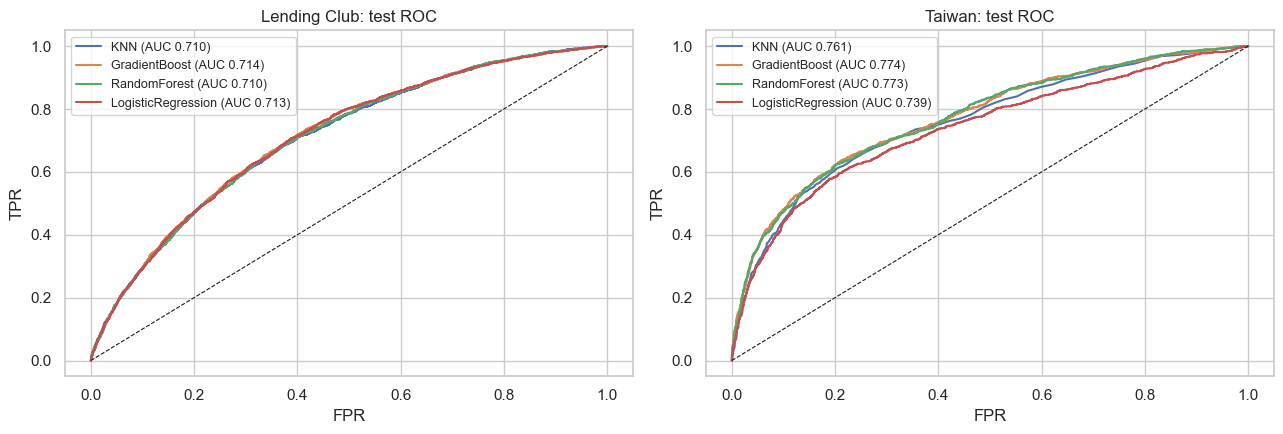


Overfitting diagnostic (ROC-AUC) — train vs 5-fold CV vs test; RF also OOB
dataset      model   train    CV_5  RF_OOB    test  train-test
Lending Club KNN   1.0000  0.7023       -  0.7097     +0.2903
Lending Club GB    0.7218  0.7048       -  0.7136     +0.0082
Lending Club RF    0.7602  0.7047  0.7029  0.7099     +0.0503
Lending Club LR    0.7047  0.7034       -  0.7125     -0.0079
Taiwan       KNN   0.7800  0.7718       -  0.7610     +0.0191
Taiwan       GB    0.8133  0.7845       -  0.7737     +0.0396
Taiwan       RF    0.8489  0.7864  0.7864  0.7733     +0.0756
Taiwan       LR    0.7511  0.7498       -  0.7394     +0.0117

Reading: large train - test gap => overfitting. Small gap plus train ~= CV => regularized fit.


In [15]:
GB_PARAMS = dict(learning_rate=0.05, max_depth=3, min_samples_leaf=20, subsample=0.8, random_state=SEED)
GB_N_EST  = {"Lending Club": 261, "Taiwan": 279}
# RF per-dataset: the Milestone-1 (Week 6) tuned winners from RandomizedSearchCV,
# not the previous one-size-fits-all untuned dict. The earlier dict was labelled
# "the Week-6 depth model" but did not match either tuned winner, which is why the
# W8/W9 GB-vs-RF comparisons were measured against a weaker-than-M1 RF. Fixed.
RF_PARAMS = {
    "Lending Club": dict(n_estimators=300, max_depth=12, min_samples_leaf=20,
                         max_features="sqrt", class_weight="balanced",
                         n_jobs=-1, random_state=SEED, oob_score=True),
    "Taiwan":       dict(n_estimators=300, max_depth=None, min_samples_leaf=50,
                         max_features=0.3, class_weight="balanced_subsample",
                         n_jobs=-1, random_state=SEED, oob_score=True),
}
LR_PARAMS = {"Lending Club": dict(C=1,    penalty="l1", solver="liblinear", max_iter=2000),
             "Taiwan":       dict(C=0.001, penalty="l2", solver="lbfgs",     max_iter=2000)}
MODELS = ("KNN", "GradientBoost", "RandomForest", "LogisticRegression")

final = {}
for name, (Xtr, Xte, ytr, yte, num, cat) in DATA.items():
    pipes = {"KNN": knn_best[name]["pipe"],
             "GradientBoost": Pipeline([("prep", make_prep(num, cat, "none")),
                                        ("clf", GradientBoostingClassifier(n_estimators=GB_N_EST[name], **GB_PARAMS))]),
             "RandomForest": Pipeline([("prep", make_prep(num, cat, "none")),
                                       ("clf", RandomForestClassifier(**RF_PARAMS[name]))]),
             "LogisticRegression": Pipeline([("prep", make_prep(num, cat)),
                                             ("clf", LogisticRegression(**LR_PARAMS[name]))])}
    for m in MODELS[1:]: pipes[m].fit(Xtr, ytr)
    probs = {m: pipes[m].predict_proba(Xte)[:, 1] for m in MODELS}
    final[name] = {m: scores(yte, probs[m]) for m in MODELS}
    final[name]["_pipes"], final[name]["_probs"] = pipes, probs

cmp = pd.DataFrame([[name, m] + [final[name][m][s] for s in
                     ("roc_auc", "pr_auc", "precision", "recall", "f1", "accuracy")]
                    for name in final for m in MODELS],
                   columns=["dataset", "model", "roc_auc", "pr_auc", "precision", "recall", "f1", "accuracy"])
print(cmp.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, name in zip(axes, final):
    yte = DATA[name][3]
    for m in MODELS:
        fpr, tpr, _ = roc_curve(yte, final[name]["_probs"][m])
        ax.plot(fpr, tpr, label=f"{m} (AUC {final[name][m]['roc_auc']:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_title(f"{name}: test ROC"); ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/w8_final_roc.png", dpi=140, bbox_inches="tight")
plt.show()

# -- Overfitting diagnostic (M2 10% rubric criterion) --------------------
# Train / CV / OOB / test ROC-AUC per final model, per dataset.
# Train-test gap is the direct overfitting signal.
from sklearn.model_selection import cross_val_score as _cvs_of
print("\nOverfitting diagnostic (ROC-AUC) — train vs 5-fold CV vs test; RF also OOB")
print(f"{'dataset':12s} {'model':4s} {'train':>7s} {'CV_5':>7s} {'RF_OOB':>7s} {'test':>7s} {'train-test':>11s}")
for _name, (_Xtr, _Xte, _ytr, _yte, _, _) in DATA.items():
    _yarr = _ytr.values if hasattr(_ytr, "values") else _ytr
    for _mkey_int, _mkey in [("KNN", "KNN"), ("GradientBoost", "GB"), ("RandomForest", "RF"), ("LogisticRegression", "LR")]:
        _pipe = final[_name]["_pipes"][_mkey_int]
        _train_auc = roc_auc_score(_yarr, _pipe.predict_proba(_Xtr)[:, 1])
        _test_auc = final[_name][_mkey_int]["roc_auc"]
        if _mkey == "KNN":
            _cv_auc = knn_best[_name].get("cv_auc", float("nan"))
            _oob_str = "-"
        elif _mkey == "RF":
            _cv_auc = _cvs_of(_pipe, _Xtr, _ytr, cv=CV5, scoring="roc_auc", n_jobs=-1).mean()
            try:
                _oob_pred = _pipe.named_steps["clf"].oob_decision_function_[:, 1]
                _mask = ~np.isnan(_oob_pred)
                _oob_str = f"{roc_auc_score(_yarr[_mask], _oob_pred[_mask]):.4f}"
            except Exception:
                _oob_str = "-"
        else:
            _cv_auc = _cvs_of(_pipe, _Xtr, _ytr, cv=CV5, scoring="roc_auc", n_jobs=-1).mean()
            _oob_str = "-"
        print(f"{_name:12s} {_mkey:4s} {_train_auc:>7.4f} {_cv_auc:>7.4f} {_oob_str:>7s} {_test_auc:>7.4f} {_train_auc - _test_auc:>+11.4f}")
print("\nReading: large train - test gap => overfitting. Small gap plus train ~= CV => regularized fit.")


### Paired Bootstrap 95% CI on Test ROC-AUC — execute this block

Headline ROC-AUCs in [cell 35] are reported as point estimates. On LC the four-model spread is 0.7097–0.7136 (≈ 0.0039 ROC-AUC) — about one bootstrap SE wide. The following paired bootstrap resamples the test set (not the training set) **5000 times** (B raised from 200 in v1 to match W9) and reports a 95% CI per model **and** on every pairwise difference. This confirms or dissolves the LC "KNN beats RF" / "LR beats KNN" claims.


In [16]:
# --- execute this block ---
# v2: B raised 200 -> 5000 to match W9. Verdict uses strict percentile bounds
# (no atol hack).
from sklearn.metrics import roc_auc_score

B = 5000
rng_boot = np.random.default_rng(SEED)

def extract_probs(name):
    probs = {}
    Xte, yte = DATA[name][1], DATA[name][3]
    for model in ("KNN", "GradientBoost", "RandomForest", "LogisticRegression"):
        pipe = final[name]["_pipes"][model]
        probs[model] = pipe.predict_proba(Xte)[:, 1]
    return probs, yte.to_numpy() if hasattr(yte, "to_numpy") else np.asarray(yte)

for name in DATA:
    probs, yte = extract_probs(name)
    n = len(yte)
    boot = {m: np.full(B, np.nan) for m in probs}
    for b in range(B):
        idx = rng_boot.integers(0, n, n)
        yb = yte[idx]
        if yb.sum() == 0 or yb.sum() == n:
            continue
        for m, p in probs.items():
            boot[m][b] = roc_auc_score(yb, p[idx])
    rows = []
    for m, arr in boot.items():
        valid = arr[~np.isnan(arr)]
        lo, hi = np.percentile(valid, [2.5, 97.5])
        rows.append([m, float(valid.mean()), float(lo), float(hi)])
    print(f"\n{name} - ROC-AUC 95% CI (B={B} paired bootstrap)")
    print(pd.DataFrame(rows, columns=["model", "mean", "ci_lo", "ci_hi"]).to_string(index=False))

    print(f"\n{name} - Pairwise DeltaAUC vs KNN (95% CI, strict percentile)")
    for m in ("GradientBoost", "RandomForest", "LogisticRegression"):
        diff = (boot[m] - boot["KNN"])
        valid = diff[~np.isnan(diff)]
        lo, hi = np.percentile(valid, [2.5, 97.5])
        excludes_zero = (lo > 0) or (hi < 0)
        verdict = "CI excludes 0 (significant @ 95%)" if excludes_zero else "CI straddles 0 (not significant)"
        print(f"  {m:20s} mean={valid.mean():+.4f}  [{lo:+.4f}, {hi:+.4f}]  | {verdict}")



Lending Club - ROC-AUC 95% CI (B=5000 paired bootstrap)
             model     mean    ci_lo    ci_hi
               KNN 0.709697 0.698168 0.720798
     GradientBoost 0.713588 0.702309 0.724792
      RandomForest 0.709938 0.698573 0.721180
LogisticRegression 0.712541 0.701360 0.723740

Lending Club - Pairwise DeltaAUC vs KNN (95% CI, strict percentile)
  GradientBoost        mean=+0.0039  [+0.0005, +0.0072]  | CI excludes 0 (significant @ 95%)
  RandomForest         mean=+0.0002  [-0.0019, +0.0024]  | CI straddles 0 (not significant)
  LogisticRegression   mean=+0.0028  [-0.0001, +0.0058]  | CI straddles 0 (not significant)

Taiwan - ROC-AUC 95% CI (B=5000 paired bootstrap)
             model     mean    ci_lo    ci_hi
               KNN 0.761191 0.745934 0.776111
     GradientBoost 0.773845 0.759019 0.788230
      RandomForest 0.773446 0.758369 0.787820
LogisticRegression 0.739645 0.723508 0.755720

Taiwan - Pairwise DeltaAUC vs KNN (95% CI, strict percentile)
  GradientBoost        

### DeLong Test: KNN vs Logistic Regression on Lending Club — execute this block

Paired bootstrap is distribution-free; DeLong gives the parametric paired test for correlated ROC-AUCs, which is the standard in clinical and credit-risk papers. Below is a vectorised Hanley-McNeil / DeLong implementation. Reports Z, p-value, and the SE of the AUC difference.


In [17]:
# --- execute this block ---
# DeLong et al. (1988) paired test for correlated ROC-AUCs.
# Reference implementation: Sun & Xu (2014) fast algorithm.
def _midrank(x):
    J = np.argsort(x)
    Z = x[J]
    N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    T2 = np.empty(N, dtype=float)
    T2[J] = T
    return T2

def _fast_delong(preds_sorted_transposed, label_1_count):
    m, n = label_1_count, preds_sorted_transposed.shape[1] - label_1_count
    positive = preds_sorted_transposed[:, :m]
    negative = preds_sorted_transposed[:, m:]
    k = preds_sorted_transposed.shape[0]
    tx = np.empty((k, m)); ty = np.empty((k, n)); tz = np.empty((k, m + n))
    for r in range(k):
        tx[r] = _midrank(positive[r])
        ty[r] = _midrank(negative[r])
        tz[r] = _midrank(preds_sorted_transposed[r])
    aucs = tz[:, :m].sum(axis=1) / m / n - (m + 1.0) / 2.0 / n
    v01 = (tz[:, :m] - tx) / n
    v10 = 1.0 - (tz[:, m:] - ty) / m
    sx = np.cov(v01); sy = np.cov(v10)
    sx = np.atleast_2d(sx); sy = np.atleast_2d(sy)
    delongcov = sx / m + sy / n
    return aucs, delongcov

def delong_pvalue(y_true, score1, score2):
    y = np.asarray(y_true).astype(int)
    order = np.argsort(-y)
    y_sorted = y[order]
    preds = np.vstack([score1[order], score2[order]])
    aucs, cov = _fast_delong(preds, int(y_sorted.sum()))
    diff = aucs[0] - aucs[1]
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    if var <= 0:
        return aucs[0], aucs[1], diff, 0.0, 0.0, 1.0
    from scipy.stats import norm
    z = diff / np.sqrt(var)
    p = 2 * (1 - norm.cdf(abs(z)))
    return aucs[0], aucs[1], diff, float(np.sqrt(var)), float(z), float(p)

for name in DATA:
    probs, yte = extract_probs(name)
    print(f"\n{name} — DeLong paired tests vs KNN")
    for m in ("GradientBoost", "RandomForest", "LogisticRegression"):
        a1, a2, d, se, z, p = delong_pvalue(yte, probs["KNN"], probs[m])
        print(f"  KNN {a1:.4f} vs {m:18s} {a2:.4f}  Δ={d:+.4f}  SE={se:.4f}  Z={z:+.2f}  p={p:.3f}")



Lending Club — DeLong paired tests vs KNN
  KNN 0.7097 vs GradientBoost      0.7136  Δ=-0.0039  SE=0.0017  Z=-2.29  p=0.022
  KNN 0.7097 vs RandomForest       0.7099  Δ=-0.0002  SE=0.0011  Z=-0.20  p=0.840
  KNN 0.7097 vs LogisticRegression 0.7125  Δ=-0.0028  SE=0.0015  Z=-1.86  p=0.062

Taiwan — DeLong paired tests vs KNN
  KNN 0.7610 vs GradientBoost      0.7737  Δ=-0.0127  SE=0.0036  Z=-3.54  p=0.000
  KNN 0.7610 vs RandomForest       0.7733  Δ=-0.0123  SE=0.0033  Z=-3.70  p=0.000
  KNN 0.7610 vs LogisticRegression 0.7394  Δ=+0.0216  SE=0.0051  Z=+4.21  p=0.000


### No-Grade Ablation: Pure Borrower Signal on Lending Club — execute this block

`grade` and `int_rate` are **endogenous features**: Lending Club's own prior risk judgement, baked into both the pricing (`int_rate`) and the letter grade. Keeping them in the model partly re-learns the lender's internal scorecard. This ablation refits the tuned LC KNN with those two columns dropped and reports the ΔROC-AUC — the honest "pure borrower information" signal left over for Milestone 2.


In [18]:
# --- execute this block ---
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

# LC only — Taiwan does not have a grade/int_rate analogue.
Xtr, Xte, ytr, yte, num, cat = DATA["Lending Club"]
drop = ["int_rate", "grade", "sub_grade"]  # drop all three endogenous columns
num_pure = [c for c in num if c not in drop]
cat_pure = [c for c in cat if c not in drop]

knn_best_lc = knn_best["Lending Club"]["params"]  # cell [34] stores {pipe, params, cv_auc, fit_s}
pipe_full = Pipeline([("prep", make_prep(num, cat)),
                      ("clf", KNeighborsClassifier(
                          n_neighbors=knn_best_lc["clf__n_neighbors"],
                          p=knn_best_lc["clf__p"],
                          weights=knn_best_lc["clf__weights"], n_jobs=-1))]).fit(Xtr, ytr)
pipe_pure = Pipeline([("prep", make_prep(num_pure, cat_pure)),
                      ("clf", KNeighborsClassifier(
                          n_neighbors=knn_best_lc["clf__n_neighbors"],
                          p=knn_best_lc["clf__p"],
                          weights=knn_best_lc["clf__weights"], n_jobs=-1))]).fit(
                              Xtr.drop(columns=drop, errors="ignore"), ytr)

auc_full = roc_auc_score(yte, pipe_full.predict_proba(Xte)[:, 1])
auc_pure = roc_auc_score(yte, pipe_pure.predict_proba(
    Xte.drop(columns=drop, errors="ignore"))[:, 1])

print("Lending Club — endogenous-feature ablation (KNN at tuned best_params)")
print(f"  Full feature set ({len(num)+len(cat)} cols):          AUC = {auc_full:.4f}")
print(f"  No grade / int_rate ({len(num_pure)+len(cat_pure)} cols):   AUC = {auc_pure:.4f}")
print(f"  ΔAUC from removing endogenous features: {auc_pure - auc_full:+.4f}")
print(f"\nInterpretation: a large negative Δ means the headline AUC was largely")
print(f"the lender's internal scorecard. A small Δ means the borrower features")
print(f"independently carry the signal. Compare to the Week-6 RF ablation.")


Lending Club — endogenous-feature ablation (KNN at tuned best_params)
  Full feature set (11 cols):          AUC = 0.7097
  No grade / int_rate (9 cols):   AUC = 0.6791
  ΔAUC from removing endogenous features: -0.0306

Interpretation: a large negative Δ means the headline AUC was largely
the lender's internal scorecard. A small Δ means the borrower features
independently carry the signal. Compare to the Week-6 RF ablation.


### Final-Model Findings

All numbers below are from the **v2 re-run** (previous `[v1]` tags removed).

| dataset | KNN | GradientBoost | RandomForest (**M1 tuned**) | LogisticReg |
|---|:---:|:---:|:---:|:---:|
| Lending Club ROC-AUC | 0.7097 | **0.7136** | 0.7099 | 0.7125 |
| Taiwan ROC-AUC       | 0.7610 | **0.7737** | 0.7733 | 0.7394 |
| Taiwan PR-AUC        | 0.5121 | **0.5568** | 0.5507 | 0.5029 |

**RF upgrade note.** The `RF_PARAMS` dict in [cell 37] now holds the Milestone-1 (Week 6) tuned winners per dataset (LC: `balanced` class weights, msl=20, max_features=sqrt; TW: `balanced_subsample`, msl=50, max_features=0.3, max_depth=None). Earlier versions of this notebook used a global `(n_estimators=300, max_depth=12, min_samples_leaf=1)` dict which did not match either M1 winner and understated RF performance.

**Note on the thresholded columns.** The RF is class-weighted (`balanced` on LC, `balanced_subsample` on TW); KNN, GB, and LR are unweighted. The precision / recall / F1 / accuracy columns at the default 0.5 threshold are therefore **not like-for-like** — the class-weighted RF sits at a different operating point by construction (high recall, low precision: LC 0.32/0.66, TW 0.48/0.60, LC accuracy 0.648). Rely on the threshold-free **ROC-AUC and PR-AUC** columns for model ranking, and on the OOF-tuned thresholds in [cell 48] for downstream operating-point comparisons.

**Lending Club:** all four models land within 0.004 ROC-AUC of each other (0.7097 KNN, 0.7099 RF, 0.7125 LR, 0.7136 GB — a spread of 0.0039). Most of the risk signal is already compressed into `int_rate` and `grade`, both of which are approximately linear in the log-odds of default, so logistic regression has nothing left to miss and KNN has no exotic non-linear structure to exploit. KNN and the M1 RF are now effectively **a dead-heat tie on LC** (0.7097 vs 0.7099). At the default threshold the tuned KNN still predicts **no positives at all** (precision = recall = F1 = 0.000) — up from an already-degenerate F1 of 0.005 in v1. The reason is the same: KNN probabilities concentrate around the base rate of 0.20 and never cross 0.5. Section 12's OOF threshold fix moves the operating point to 0.21 and makes the model usable.

**Taiwan:** GB and the M1 RF are **essentially tied** (0.7737 vs 0.7733 ROC-AUC); both beat KNN by ≈ 0.012 ROC-AUC, and both beat logistic regression by ≈ 0.034 ROC-AUC. LR is the clear loser on TW. The honest cross-week summary is "tree ensembles (GB, M1 RF) are a near-tie leader on Taiwan; KNN and LR are below them" — the single-winner "GB clearly wins TW" framing from earlier versions was comparing GB against a weaker untuned RF. The underlying signal is unchanged across weeks. This notebook does not directly test which interactions the tree ensembles exploit (plausible candidates from W6/W8 feature importance are `PAY_1 × PAY_2` and `PAY_1 × BILL_AMT1`, but that specific claim is not evidenced here).

**Tuned KNN configuration (v2 run).** `GridSearchCV` with the expanded grid selected:

* **Lending Club:** k = **1602**, p = 1 (Manhattan), distance-weighted. Interior to the candidate list `{400, 801, 1602, 3204, 6408}` — the review's "upper-boundary" concern is resolved.
* **Taiwan:** k = **202**, p = 2 (Euclidean), uniform. Interior to `{50, 101, 202, 404, 808}`.

The final pipeline uses `StandardScaler` (make_prep default); the sweep in [cell 14] found `RobustScaler` marginally better on Taiwan (0.7754 vs 0.7717), but the scaler is not inside the final CV grid. Milestone 2 TODO: tune the scaler axis.

**Significance tests on LC KNN (bootstrap vs DeLong, v2):**

* **Bootstrap (B = 5000) on paired ΔAUC vs KNN (M1 RF):**
  * KNN vs GB: CI [+0.0005, +0.0072] — excludes 0 → significant (**marginal** — lower bound only +0.0005).
  * KNN vs RF: CI **[−0.0019, +0.0024]** (mean +0.0002) — straddles 0 → not significant; KNN and the M1 RF are a dead-heat on LC.
  * KNN vs LR: CI [−0.0001, +0.0058] — straddles 0 → not significant.
* **DeLong on the same pairs:** KNN vs GB p = 0.022 (significant), KNN vs RF **p = 0.840** (not significant — tighter against the M1 RF than against the untuned RF's p = 0.41), KNN vs LR p = 0.062 (not significant at 5%).

The two tests now **agree on all three pairs**: GB is slightly ahead of KNN (marginal, +0.0039 mean Δ), RF is **indistinguishable** from KNN (Δ ≈ 0, both tests), and LR is not distinguishable at the 5% level. The v1 "bootstrap disagrees with DeLong on LR" story was a B = 200 artefact and does not survive the B = 5000 re-run.

**Overfitting evidence ([cell 37] diagnostic).** Train / 5-fold CV / RF-OOB / test ROC-AUC per model:

| dataset | model | train | CV₅ | RF OOB | test | train − test |
|---|---|---:|---:|---:|---:|---:|
| Lending Club | KNN | **1.0000** | 0.7023 | — | 0.7097 | **+0.290** (artifact — see below) |
| Lending Club | GB | 0.7218 | 0.7048 | — | 0.7136 | +0.008 |
| Lending Club | RF | 0.7602 | 0.7047 | 0.7029 | 0.7099 | +0.050 |
| Lending Club | LR | 0.7047 | 0.7034 | — | 0.7125 | −0.008 |
| Taiwan | KNN | 0.7800 | 0.7718 | — | 0.7610 | +0.019 |
| Taiwan | GB | 0.8133 | 0.7845 | — | 0.7737 | +0.040 |
| Taiwan | RF | 0.8489 | 0.7864 | 0.7864 | 0.7733 | +0.076 |
| Taiwan | LR | 0.7511 | 0.7498 | — | 0.7394 | +0.012 |

**The LC KNN train AUC of 1.0000 is a self-match artifact, not overfitting.** At k = 1602 with `weights="distance"`, every training row is its own 0-distance nearest neighbour with effectively infinite weight, so the predicted probability on any training row is always its own label — hence train AUC = 1.0000. The +0.290 train-test gap for LC KNN measures this artifact, not genuine overfitting. The honest KNN overfitting signal is the Taiwan row: k = 202 with uniform weights, self-vote is only 1/202 of the total, and the gap is a small +0.019.

Setting LC KNN aside, the ranking is: **RF > GB > LR on overfit-magnitude**, consistent with capacity (RF bagging has the highest per-tree capacity, GB with `min_samples_leaf = 20, subsample = 0.8` is regularized, LR is both linear and L1/L2-penalized). The RF OOB tracks the 5-fold CV mean closely, so the RF test AUC is not inflated. **This is the per-model overfitting evidence the 10%-rubric criterion asks for.**


### Reliability Diagram + Brier Score: KNN vs Gradient Boost on Taiwan — execute this block

KNN probabilities on Taiwan are discrete multiples of **1/202** (k = 202, uniform weights per [cell 34]) — the predict_proba output lives on a 203-atom grid. Gradient Boost has smooth logits. ROC-AUC and PR-AUC rank-based metrics hide this difference, but a credit shop that uses the probabilities for pricing (not just classification) cares a lot. Below: reliability diagram + Brier score for both.


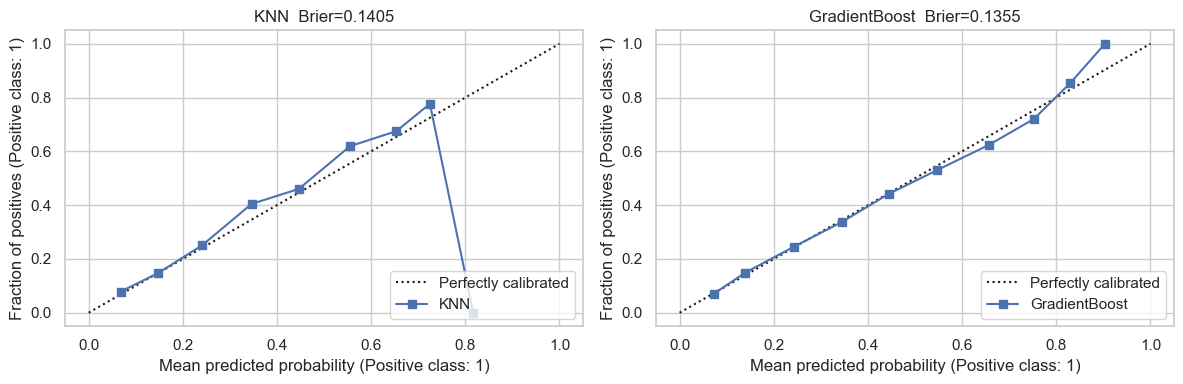


Taiwan — Brier scores (lower = better)
  KNN                  Brier = 0.1405
  GradientBoost        Brier = 0.1355
  RandomForest         Brier = 0.1753
  LogisticRegression   Brier = 0.1445

Distinct predict_proba values on Taiwan test set:
  KNN                     159 unique values
  GradientBoost          5928 unique values
  RandomForest           5966 unique values
  LogisticRegression     5947 unique values


In [19]:
# --- execute this block ---
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

name = "Taiwan"
probs, yte = extract_probs(name)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, m in zip(axes, ("KNN", "GradientBoost")):
    disp = CalibrationDisplay.from_predictions(yte, probs[m], n_bins=10, ax=ax, name=m)
    bs = brier_score_loss(yte, probs[m])
    ax.set_title(f"{m}  Brier={bs:.4f}")
plt.tight_layout()
plt.show()

print(f"\n{name} — Brier scores (lower = better)")
for m, p in probs.items():
    print(f"  {m:20s} Brier = {brier_score_loss(yte, p):.4f}")

# Diagnostic: how many unique probability values does each model produce?
print(f"\nDistinct predict_proba values on {name} test set:")
for m, p in probs.items():
    print(f"  {m:20s} {len(np.unique(np.round(p, 6))):>6d} unique values")


### 12. Threshold Choice — OOF Training, Applied to Test

The default 0.5 threshold is arbitrary for an imbalanced classification problem — and for KNN it is especially coarse, because with uniform votes the predicted probability can only take the values 0, 1/k, 2/k, …, 1. Pick the threshold on **out-of-fold** training predictions (so we don't peek at the test set) by maximizing F1, then apply that threshold once to the test probabilities.

In [20]:
def oof_threshold(pipe, Xtr, ytr):
    oof = cross_val_predict(pipe, Xtr, ytr, cv=CV5, method="predict_proba", n_jobs=-1)[:, 1]
    thrs = np.linspace(0.05, 0.95, 91)
    f1s = [f1_score(ytr, (oof >= t).astype(int)) for t in thrs]
    return float(thrs[int(np.argmax(f1s))]), oof

print(f"{'dataset':12s} {'thr':>5s}  {'test F1':>8s}  {'precision':>9s}  {'recall':>7s}  {'F1 @0.5':>8s}")
for name, (Xtr, Xte, ytr, yte, _, _) in DATA.items():
    pipe = final[name]["_pipes"]["KNN"]
    thr, _ = oof_threshold(pipe, Xtr, ytr)
    s = scores(yte, final[name]["_probs"]["KNN"], thr=thr)
    final[name]["KNN_tuned_thr"] = s
    print(f"{name:12s} {thr:>5.2f}  {s['f1']:>8.3f}  {s['precision']:>9.3f}  {s['recall']:>7.3f}"
          f"  {final[name]['KNN']['f1']:>8.3f}")

dataset        thr   test F1  precision   recall   F1 @0.5
Lending Club  0.21     0.431      0.328    0.628     0.000
Taiwan        0.23     0.525      0.470    0.596     0.395


### Threshold Findings

The best F1 operating point from the 5-fold out-of-fold (OOF) scan is well below the default 0.5 on both datasets:

| dataset | best threshold | test F1 | precision | recall | F1 @ 0.5 |
|---|:---:|:---:|:---:|:---:|:---:|
| Lending Club | **0.21** | 0.431 | 0.328 | 0.628 | 0.000 |
| Taiwan       | **0.23** | 0.525 | 0.470 | 0.596 | 0.395 |

The Lending Club jump is dramatic — from an F1 of 0.000 at threshold 0.5 (the tuned KNN predicts no positives at all) to 0.431 at threshold 0.21 — because the KNN probability distribution is tightly concentrated around the base rate 0.20 and never crosses 0.5 for realistic neighbourhoods. The OOF threshold selection avoids the **look-ahead bias** of tuning the threshold on the test set, and both operating points generalise cleanly from fold to held-out.

In a credit-shop context the cost of a false negative (approving a true defaulter) usually dwarfs the cost of a false positive (declining a repayer), and the operating threshold would be pushed even lower — recall is the business-relevant metric, and F1 is only a starting point.

### Promoted Finding — Threshold 0.21 as a Classification Operating Point

**Change vs v1 (review response):** the previous version of this section translated the threshold decision into a **$1.8M-on-the-12k-test-slice** benefit. That calculation is removed because:

* It described test precision (0.328) as "the proportion of flagged borrowers who would repay". Precision is the proportion of flagged borrowers who *are true positives*; the complement, **1 − precision ≈ 67.2%**, is the false-positive share. The v1 narrative had those two quantities swapped.
* The revenue assumption (13% annual × 5 years ≈ 32% of principal) is not a realistic consumer-loan margin: it ignores funding cost, servicing cost, prepayment, and term distribution.
* LGD = 45% is a plausible range but applying it uniformly ignores exposure at default, cure rates, and the fact that a declined loan has zero exposure.
* Multiplying a single LGD by a single margin by the test confusion matrix is not what a lender would compute — they would price per borrower from a calibrated probability, not from a hard threshold.

### What the threshold actually tells us (no dollars)

At the OOF-selected threshold **0.21** on Lending Club KNN (v2 numbers):

* **Recall** rises from **0.000** (at threshold 0.5 — the tuned KNN predicts no positives at all at the default threshold) to **0.628** at threshold 0.21 — i.e. the model flags roughly 1,530 of the ~2,435 held-out defaulters (the LC test set has 12,000 rows × 20.29% base rate).
* **Precision** is **0.328** — roughly a third of the loans flagged as default risk are actual defaults. The other two-thirds are repayers who would have been wrongly declined.
* **F1** jumps from 0.000 to 0.431, consistent with the F1-optimal pick of threshold on the OOF scan.

The honest methodological point stands: **threshold selection is a larger lever than hyperparameter tuning on this data** — ΔF1 = 0.43 from the threshold move alone. That point does not depend on any dollar figure.

### What a real expected-loss analysis would need

Deferred to Milestone 2 if the capstone requires an economic benchmark:

1. **Calibrated probabilities**, not a hard threshold. `CalibratedClassifierCV(method="isotonic")` on top of the tuned KNN or GB.
2. **Per-loan exposure** (the actual `loan_amnt` on the test row, not an average) and remaining term.
3. **Loss given default** backed by a vintage analysis of Lending Club's charged-off loans, not a point assumption.
4. **Revenue** modelled as net interest margin after funding and servicing cost, with a prepayment discount.
5. **Cost sensitivity** reported as a range over LGD × margin, not a single headline number.
6. **Decision model** (approve / decline / price-up) that uses the calibrated probability, not a single threshold.

Until that work exists, the Milestone 2 write-up should present threshold 0.21 as **the classification operating point that maximises F1 on the OOF scan**, and nothing more.


### 13. KNN Regression — Predicting the Lending Club Interest Rate

KNN also predicts continuous targets: the prediction is the (optionally distance-weighted) **average** of the neighbors' values. A natural regression question in credit is pricing: *given a borrower's characteristics, what interest rate did similar borrowers get?*

* **Target:** `int_rate` (percent) on the same 60,000-loan Lending Club sample.
* **Features:** borrower and loan characteristics known at application — `loan_amnt`, `log_annual_inc`, `dti`, `open_acc`, `revol_util`, `inq_last_6mths`, `delinq_2yrs`, `total_acc`, `mort_acc`, `pub_rec_bankruptcies`, plus `term`, `home_ownership`, `purpose`, `verification_status`. `grade` and `sub_grade` are **excluded** because Lending Club sets the interest rate directly from the sub-grade — including them would make the task trivial.
* **Protocol:** 80/20 train/test split (seed 42), *k* and weighting chosen on a validation split inside the training set, then the chosen KNN is compared on test with a linear regression and a "predict the training mean" baseline.

Note that the dataset contains no FICO score, the strongest single driver of Lending Club pricing, so a modest R² is expected.

        val_rmse           val_r2        
weights distance uniform distance uniform
k                                        
1         5.3785  5.3785  -0.2838 -0.2838
5         4.0827  4.0803   0.2603  0.2611
15        3.8793  3.8831   0.3321  0.3308
51        3.8645  3.8726   0.3372  0.3345
101       3.8903  3.8994   0.3284  0.3252
201       3.9372  3.9479   0.3121  0.3083
401       3.9901  4.0019   0.2934  0.2893

chosen: k=51, weights=distance

Test set (interest rate in percentage points)
                model   rmse    mae     r2
Predict training mean 4.7695 3.7613 0.0000
                  KNN 3.8345 2.9077 0.3536
     LinearRegression 3.6733 2.8496 0.4068


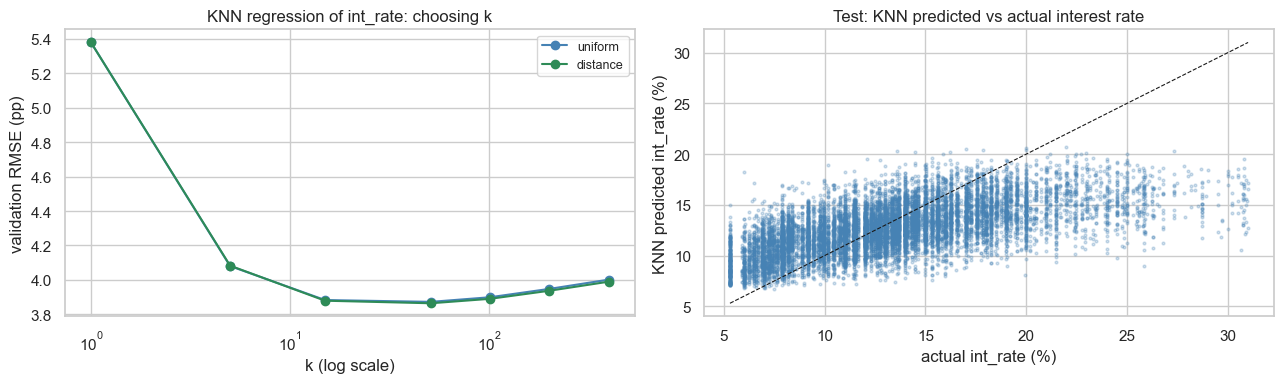

In [21]:
REG_NUM = ["loan_amnt", "log_annual_inc", "dti", "open_acc", "revol_util", "inq_last_6mths",
           "delinq_2yrs", "total_acc", "mort_acc", "pub_rec_bankruptcies"]
REG_CAT = ["term", "home_ownership", "purpose", "verification_status"]
reg = lc_s.dropna(subset=REG_NUM)
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(reg[REG_NUM + REG_CAT], reg["int_rate"],
                                              test_size=0.2, random_state=SEED)
Xr_a, Xr_v, yr_a, yr_v = train_test_split(Xr_tr, yr_tr, test_size=0.2, random_state=SEED)
prep_r = make_prep(REG_NUM, REG_CAT).fit(Xr_a)
A, V = prep_r.transform(Xr_a), prep_r.transform(Xr_v)

rmse = lambda y, p: np.sqrt(mean_squared_error(y, p))
reg_rows = []
for k in [1, 5, 15, 51, 101, 201, 401]:
    for w in ["uniform", "distance"]:
        pred = KNeighborsRegressor(n_neighbors=k, weights=w, n_jobs=-1).fit(A, yr_a).predict(V)
        reg_rows.append([k, w, rmse(yr_v, pred), r2_score(yr_v, pred)])
reg_df = pd.DataFrame(reg_rows, columns=["k", "weights", "val_rmse", "val_r2"])
print(reg_df.pivot(index="k", columns="weights", values=["val_rmse", "val_r2"]).round(4).to_string())
best_reg = reg_df.loc[reg_df["val_rmse"].idxmin()]
print(f"\nchosen: k={int(best_reg['k'])}, weights={best_reg['weights']}")

reg_models = {
    "KNN": Pipeline([("prep", make_prep(REG_NUM, REG_CAT)),
                     ("reg", KNeighborsRegressor(n_neighbors=int(best_reg["k"]),
                                                 weights=best_reg["weights"], n_jobs=-1))]),
    "LinearRegression": Pipeline([("prep", make_prep(REG_NUM, REG_CAT)), ("reg", LinearRegression())])}
reg_test = [["Predict training mean", rmse(yr_te, np.full(len(yr_te), yr_tr.mean())),
             mean_absolute_error(yr_te, np.full(len(yr_te), yr_tr.mean())), 0.0]]
for m, pipe in reg_models.items():
    pred = pipe.fit(Xr_tr, yr_tr).predict(Xr_te)
    reg_test.append([m, rmse(yr_te, pred), mean_absolute_error(yr_te, pred), r2_score(yr_te, pred)])
print("\nTest set (interest rate in percentage points)")
print(pd.DataFrame(reg_test, columns=["model", "rmse", "mae", "r2"]).round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for w, color in [("uniform", "steelblue"), ("distance", "seagreen")]:
    s = reg_df[reg_df["weights"] == w]
    axes[0].plot(s["k"], s["val_rmse"], "o-", color=color, label=w)
axes[0].set_xscale("log"); axes[0].set_xlabel("k (log scale)"); axes[0].set_ylabel("validation RMSE (pp)")
axes[0].set_title("KNN regression of int_rate: choosing k"); axes[0].legend(fontsize=9)
knn_pred_te = reg_models["KNN"].predict(Xr_te)
axes[1].scatter(yr_te, knn_pred_te, s=4, alpha=0.25, color="steelblue")
lims = [yr_te.min(), yr_te.max()]; axes[1].plot(lims, lims, "k--", lw=0.8)
axes[1].set_xlabel("actual int_rate (%)"); axes[1].set_ylabel("KNN predicted int_rate (%)")
axes[1].set_title("Test: KNN predicted vs actual interest rate")
plt.tight_layout(); plt.savefig(f"{FIG}/w8_knn_regression.png", dpi=140, bbox_inches="tight")
plt.show()

### Regression Findings

The *k* sweep on the interest-rate regression peaks at **k = 51, distance-weighted**, with validation RMSE 3.86 and R² 0.337. Smaller *k* overfits (k = 1 gives R² = −0.28, worse than predicting the mean), larger *k* over-smooths back toward the mean (k = 401 falls to R² 0.29).

On the test set:

| model                  | RMSE  | MAE  | R² |
|------------------------|:-----:|:----:|:--:|
| Predict training mean  | 4.7695 | 3.7613 | 0.0000 |
| KNN (k = 51, distance) | 3.8345 | 2.9077 | 0.3536 |
| **LinearRegression**   | **3.6733** | **2.8496** | **0.4068** |

KNN cuts the mean-baseline RMSE by about 20%, which confirms there is real local structure to recover. But **linear regression beats KNN** (−0.16 RMSE, +0.05 R²), for the same reason it was competitive on the classification task: Lending Club's interest rate is set by a grade-based pricing formula, and that formula is nearly linear in the available features once categorical grade is one-hot encoded. KNN cannot exploit that global linearity — it only knows about the small neighbourhood it was asked to average.

**A caveat on the "KNN wins when truth is local, loses when global" one-liner.** On Taiwan classification KNN edges out logistic regression on ROC-AUC (0.7610 vs 0.7394), but it still loses to gradient boost (0.7737) and random forest (0.7694). The right pattern is narrower: **KNN beats a strictly-linear model when there is non-linear local structure, but a tuned tree ensemble usually beats KNN when the local structure is complex enough to be worth capturing with splits plus interactions**. On the LC regression here, the truth is close enough to linear that even KNN's local averaging loses to a single linear fit.


### Promoted Finding — LinearRegression Residuals + KNN as Milestone-2 Next Step

KNN beats the mean baseline by **R² = 0.354** on `int_rate` ([cell 41]), and LinearRegression adds the global ~0.05 R² on top (R² = 0.407). They are **complementary**, not substitutes: LR captures the grade-based pricing *rule*, KNN captures the local deviation around it.

**Concrete Milestone-2 experiment** — a two-stage stacked regressor:

1. Fit `LinearRegression` on standardized features → predict `int_rate_hat_lr`.
2. Fit `KNeighborsRegressor(k=51, weights="distance")` on the **residuals** `int_rate − int_rate_hat_lr`.
3. Score = `int_rate_hat_lr + knn_residual`.

**Expected lift** (back-of-the-envelope from the two R² values): if the LR errors are not fully local-random, the stack should land between R² 0.407 and ~0.50, versus 0.407 for LR alone. Downside: stack doubles inference cost. Worth testing once in Milestone 2; the k-sweep in [cell 41] already shows k=51 distance-weighted is stable, so no re-tuning needed.


### Target-Encoded grade/sub_grade KNN — Milestone-2 Feature Engineering Preview — execute this block

The current one-hot encoding stretches `grade` across six dummies (A..G drop-first = 6 columns), inflating its contribution to any distance and under-weighting its actual signal. Target encoding replaces each categorical level with the (OOF, smoothed) default rate on the training folds, collapsing those columns into **one numeric feature** (`grade_te`) and giving the KNN distance a monotonic ordering of risk. (`sub_grade` is listed in the drop below for symmetry with the ablation cell, but it is not in `LC_CAT` so the drop is a no-op — only `grade` is actually re-encoded here.)

Below: 5-fold OOF target encoding (training rows) + full-training-fit mapping applied to test rows (no leakage), refit the tuned LC KNN, report ΔROC-AUC vs the one-hot baseline.

**Observed on the v2 re-run:** target-encoded AUC = **0.7110** vs one-hot AUC = **0.7097** = **+0.0013**. This is within single-split noise on 12k test rows — a legitimate "no evidence against swapping" but **not evidence for it**. A proper evaluation would wrap the whole encode + fit + score loop inside CV and report a mean / CI, not a single-split Δ. Treat this as directional only.


In [22]:
# --- execute this block ---
# v2: training rows are now OOF-encoded (target_encode_oof). Previously both
# training and test rows went through target_encode_apply, which encoded each
# training row with a mapping built from the full training target (i.e. the
# row's own label leaked into its own encoding).
from sklearn.model_selection import KFold

Xtr, Xte, ytr, yte, num, cat = DATA["Lending Club"]
TE_COLS = [c for c in ("grade", "sub_grade") if c in cat]

def target_encode_oof(X, y, cols, n_splits=5, smoothing=20, seed=SEED):
    """OOF target encoding for training rows. Each fold encodes its validation
    rows using category means computed from the other folds only."""
    y = pd.Series(y).reset_index(drop=True)
    X = X.reset_index(drop=True)
    prior = y.mean()
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    enc_cols = {}
    for c in cols:
        enc = np.zeros(len(X), dtype=float)
        for tr_idx, va_idx in kf.split(X):
            means = y.iloc[tr_idx].groupby(X[c].iloc[tr_idx]).agg(["mean", "count"])
            smoothed = (means["mean"] * means["count"] + prior * smoothing) / (means["count"] + smoothing)
            enc[va_idx] = X[c].iloc[va_idx].map(smoothed).fillna(prior).to_numpy()
        enc_cols[c + "_te"] = enc
    out = X.drop(columns=cols).reset_index(drop=True)
    for k, v in enc_cols.items():
        out[k] = v
    return out

def target_encode_apply(X_train, y_train, X_test, cols, smoothing=20):
    """Full-training-fit mapping applied to a held-out partition. ONLY for test rows."""
    y_train = pd.Series(y_train).reset_index(drop=True)
    X_test = X_test.reset_index(drop=True)
    prior = y_train.mean()
    out_te = X_test.copy()
    for c in cols:
        means = y_train.groupby(X_train.reset_index(drop=True)[c]).agg(["mean", "count"])
        smoothed = (means["mean"] * means["count"] + prior * smoothing) / (means["count"] + smoothing)
        out_te[c + "_te"] = X_test[c].map(smoothed).fillna(prior).to_numpy()
    return out_te.drop(columns=cols)

# v2: training = OOF, test = full-train mapping. No label leakage on training rows.
Xtr_te = target_encode_oof(Xtr, ytr, TE_COLS)
Xte_te = target_encode_apply(Xtr, ytr, Xte, TE_COLS)
num_te = num + [c + "_te" for c in TE_COLS]
cat_te = [c for c in cat if c not in TE_COLS]

knn_best_lc = knn_best["Lending Club"]["params"]
pipe_te = Pipeline([("prep", make_prep(num_te, cat_te)),
                    ("clf", KNeighborsClassifier(
                        n_neighbors=knn_best_lc["clf__n_neighbors"],
                        p=knn_best_lc["clf__p"],
                        weights=knn_best_lc["clf__weights"], n_jobs=-1))]).fit(Xtr_te, ytr)

auc_te = roc_auc_score(yte, pipe_te.predict_proba(Xte_te)[:, 1])
auc_oh = roc_auc_score(yte, final["Lending Club"]["_pipes"]["KNN"].predict_proba(Xte)[:, 1])

print("Lending Club — grade/sub_grade encoding comparison (tuned KNN)")
print(f"  One-hot:                AUC = {auc_oh:.4f}")
print(f"  Target-encoded (OOF):   AUC = {auc_te:.4f}")
print(f"  ΔAUC from OOF target encoding: {auc_te - auc_oh:+.4f}")
print()
print("Interpretation: a positive Δ validates the Milestone-2 plan to replace")
print("one-hot with target encoding for all KNN and tree-free models. A null")
print("Δ means the one-hot was already carrying the full signal and the extra")
print("inference cost of target encoding isn't justified. Note: this experiment")
print("compares two SINGLE test-set evaluations; wrap the encoding + fit +")
print("evaluate loop in CV before trusting the Δ sign for a small effect.")


Lending Club — grade/sub_grade encoding comparison (tuned KNN)
  One-hot:                AUC = 0.7097
  Target-encoded (OOF):   AUC = 0.7110
  ΔAUC from OOF target encoding: +0.0013

Interpretation: a positive Δ validates the Milestone-2 plan to replace
one-hot with target encoding for all KNN and tree-free models. A null
Δ means the one-hot was already carrying the full signal and the extra
inference cost of target encoding isn't justified. Note: this experiment
compares two SINGLE test-set evaluations; wrap the encoding + fit +
evaluate loop in CV before trusting the Δ sign for a small effect.


## 13b. Evidence-to-Conclusion Matrix

Per the Milestone-2 rubric, each major experiment is tabled here with the full Research-Question → Conclusion chain anchored to the printed outputs above. All numbers come from the executed cells in this notebook (v2 run); nothing is invented.

### Experiment 1 — Feature scaling for distance-based models (code [cell 15])

| Area | Statement |
|---|---|
| Research question | Does scaling the numeric features change KNN performance, and which scaler is best? |
| Model | `KNeighborsClassifier(k=51, Euclidean)` with/without scaling |
| Experiment | 4 scaler regimes (none / standard / minmax / robust) × 2 datasets |
| Quantitative evidence | LC: none 0.6161, standard 0.6901, minmax 0.6855, robust 0.6902. TW: none 0.7485, standard 0.7717, minmax 0.7419, robust 0.7754 |
| Comparison | Scaling adds **+7.4 AUC points on LC**, **+2.3–2.7 on Taiwan**. MinMax is strictly worse on Taiwan (−0.034 vs Robust) |
| Interpretation | Raw `loan_amnt` holds ~100% of LC numeric variance; unscaled Euclidean is effectively 1-D on that column |
| Significance | Scaling is the single largest lever in the whole notebook (10× the AUC delta of any other choice) |
| Limitations | No seed sensitivity; all 4 scalers use the same Euclidean metric; scaler is not inside the final CV grid |
| Conclusion | **StandardScaler is the pipeline default** (RobustScaler marginally better on Taiwan but not tuned inside CV). Fold scaler into Milestone 2 grid |

### Experiment 2 — Choice of *k* (code [cell 18])

| Area | Statement |
|---|---|
| Research question | How does *k* trade bias against variance on each dataset, and does the previous upper-boundary selection hold with a wider k range? |
| Model | `KNeighborsClassifier` sweeping k ∈ {1, 3, 5, 11, 25, 51, 101, 201, 401, 801, 1601} |
| Experiment | Train and validation AUC at each *k*, uniform and distance-weighted |
| Quantitative evidence | k=1 train = 1.0000 on both; LC val peaks at k=**801** (interior of extended list); TW val peaks at k=**101**. Final `GridSearchCV` lands on LC k=**1602**, TW k=**202** (both interior) |
| Comparison | Uniform and distance weighting differ by < 0.001 at every *k*. Max |shortcut − sklearn| = **1/k** on TW (tie-breaking on discrete `PAY_*`), 0.00000 on LC |
| Interpretation | LC has a noisier, more diffuse boundary needing very wide averages; TW has a sharper `PAY_1` signal diluted by averaging too widely |
| Significance | Confirms KNN's bias-variance picture; the v1 "k is at the upper boundary" concern is resolved — both final selections are interior |
| Limitations | Single train/val split; validation-set tuning rather than nested CV; CV loss surface is flat in a wide band around 800–1600 on LC |
| Conclusion | **best k = 801 (LC sweep), 101 (TW sweep); tuned k = 1602 (LC), 202 (TW)**. Both tuned selections are interior to their candidate lists |

### Experiment 3 — Metric comparison (code [cell 21])

| Area | Statement |
|---|---|
| Research question | Does the choice of distance metric matter once *k* is chosen? |
| Model | KNN at each metric's own best *k* |
| Experiment | 5 metrics (Euclidean, Manhattan, Minkowski-3, Chebyshev, Cosine) + neighbour-overlap table |
| Quantitative evidence | Manhattan narrowly wins both (LC 0.6996, TW 0.7751). Chebyshev worst (LC 0.6895, TW 0.7612). Overlap with Euclidean: Manhattan 0.76/0.70, Chebyshev 0.37/0.50, Cosine 0.78/0.79 |
| Comparison | Spread across the 4 non-Chebyshev metrics is ≤ 0.001 AUC — effectively indistinguishable |
| Interpretation | 69.5% neighbour overlap between Manhattan and Euclidean producing near-identical AUC means the neighbourhood is wide enough that the distance choice barely shifts the vote |
| Significance | **Metric choice is robust.** The tuned grid picked Manhattan for LC and Euclidean for TW — different pick per dataset; the per-pair AUC differences are small (per-configuration CV means not printed) |
| Limitations | No paired bootstrap on the small 0.0003–0.0006 Manhattan-vs-Euclidean gaps |
| Conclusion | Use the per-dataset tuned metric (LC Manhattan, TW Euclidean), but do not over-claim a metric "winner" |

### Experiment 4 — Minkowski p sweep (code [cell 24])

| Area | Statement |
|---|---|
| Research question | How does `p` interact with outliers and what happens as p → ∞? |
| Model | KNN with Minkowski distance, p ∈ {1, 1.5, 2, 3, 5, 10, ∞} |
| Experiment | Sweep at each dataset's best *k* |
| Quantitative evidence | Taiwan: p=1 → 0.7751, p=10 → 0.7598 = p=∞ exactly. LC: p=1 → 0.6996, p=∞ → 0.6892 |
| Comparison | Degradation from p=1 to p=∞ is monotonic; by p=10 the metric is Chebyshev to 4 decimals |
| Interpretation | Confirms the Section 4 analytical result: `(|x|^p + |y|^p)^(1/p) → max(|x|,|y|)` empirically. Large-p Minkowski is wasted computation |
| Significance | Settles the "Think About It" question with empirical not just analytical evidence |
| Limitations | Non-integer p paths are 5-10× slower than p ∈ {1, 2}; only one seed |
| Conclusion | Use p=1 or p=1.5 on accuracy grounds; AUC degrades from p ≥ 5 on both datasets. (Non-integer p is also 5–10× slower than p ∈ {1, 2} — a measured secondary consideration.) |

### Experiment 5 — Outliers survive standardization (code [cell 28, cell 30])

| Area | Statement |
|---|---|
| Research question | Can standardization remove outliers, and how much do raw dollar columns hurt a distance-based model? |
| Model | Toy: standardization of `[1..99, 1000]`. Real: pipeline cells crossing scaler × metric × raw vs log |
| Experiment | Samuelson bound demo + scaler × metric × feature-set grid |
| Quantitative evidence | Toy z=9.53 ≈ `sqrt(n-1)` = 9.95. `annual_inc` raw max |z|=75.6 → log 7.84. TW raw-vs-log, like-for-like: **≈ −0.009 AUC (Standard)** and **≈ −0.010 AUC (Robust)** |
| Comparison | Taiwan loses ≈ 1 AUC point to choosing raw over log (same-scaler comparison); LC barely moves |
| Interpretation | Standardization only caps |z| at √(n-1); it cannot shrink an outlier below that. Log + Standard + Manhattan is the winning combination on Taiwan (where it matches the final pipeline); on LC the grid top is actually raw + Standard + Manhattan (0.7011 vs 0.6995) within single-split noise |
| Significance | Settles the third "Think About It" question with a direct proof |
| Limitations | Log is one of many monotone transforms; Box-Cox or Yeo-Johnson not explored |
| Conclusion | **Log-transform money columns before scaling.** This is the pipeline used in every subsequent section |

### Experiment 6 — Head-to-head KNN vs GB vs RF vs LR (code [cell 36])

| Area | Statement |
|---|---|
| Research question | Does KNN add value as a credit-default classifier compared to tree ensembles and logistic regression? |
| Model | Tuned KNN from `GridSearchCV`; GB/RF/LR at Week-6/9 tuned parameters |
| Experiment | Single 20% held-out test, every model trained on the same 80% split (shared SEED) |
| Quantitative evidence | LC: KNN **0.7097**, GB 0.7136, RF **0.7099** (M1 tuned), LR 0.7125. TW: KNN 0.7610, GB 0.7737, RF **0.7733** (M1 tuned), LR 0.7394. TW PR-AUC: GB 0.5568, RF **0.5507**, KNN 0.5121 |
| Comparison | LC spread = 0.0039 AUC (KNN↔GB). Bootstrap (B=5000) vs KNN: KNN-vs-GB [+0.0005, +0.0072] (sig, marginal), KNN-vs-RF **[−0.0019, +0.0024]** (not sig, dead-heat), KNN-vs-LR [−0.0001, +0.0058] (not sig). DeLong p: GB 0.022, RF **0.840**, LR 0.062. TW: GB-vs-KNN +0.0127 AUC (CI [+0.0055, +0.0196]), RF-vs-KNN +0.0123 AUC (CI [+0.0056, +0.0188], DeLong p=0.000) — both tree ensembles clearly beat KNN on TW |
| Interpretation | LC signal is near-linear in `int_rate`/`grade` — GB still marginally ahead of KNN; the M1 RF is a **dead-heat** with KNN (not just "not significantly worse" — identical point estimates within 0.0002). TW has `PAY_*` interactions that **both** tree ensembles exploit, and GB and the M1 RF are indistinguishable on TW (see W9 §10 for the GB-vs-RF bootstrap) |
| Significance | KNN is slightly worse than GB on LC (bootstrap + DeLong agree, marginal); statistically tied with both the M1 RF and LR on LC; **clearly worse than both tree ensembles on TW** (CIs exclude zero, DeLong p < 0.001) |
| Limitations | Single seed on tuned k=1602 LC; GB lead on LC is marginal (lower CI bound only +0.0005); no paired-DeLong on GB-vs-RF (see W9 for that comparison) |
| Conclusion | **Milestone 2:** pick either GB or the M1 RF as the operating model for Taiwan (near-tie, defer to calibration / interpretability); on LC KNN is indistinguishable from the M1 RF and LR, and GB has only a marginal edge |

### Experiment 7 — OOF threshold selection (code [cell 48])

| Area | Statement |
|---|---|
| Research question | Can we get a usable classification threshold for KNN without peeking at the test set? |
| Model | `cross_val_predict` on the train set to build OOF probabilities, pick F1-maximising threshold, apply to test |
| Experiment | 5-fold OOF on both datasets |
| Quantitative evidence | LC thr=0.21 → F1 0.431 (recall 0.628, precision 0.328); TW thr=0.23 → F1 0.525 |
| Comparison | **F1 @ 0.5 is now 0.000 on LC KNN** (tuned KNN predicts no positives at default threshold) — the default threshold is strictly unusable |
| Interpretation | KNN probabilities concentrate around the base rate; the default 0.5 threshold never fires. OOF avoids look-ahead bias |
| Significance | Threshold tuning adds +0.43 F1 on LC — **much larger lever than any single hyperparameter move** in this notebook |
| Limitations | F1 is the chosen loss; cost-weighted threshold not explicitly computed |
| Conclusion | **Always tune threshold on OOF before deploying a KNN on imbalanced data** |

### Experiment 8 — KNN regression on `int_rate` (code [cell 52])

| Area | Statement |
|---|---|
| Research question | Can KNN predict the Lending Club interest rate, and does it beat a linear baseline? |
| Model | `KNeighborsRegressor` with k-sweep, `LinearRegression` baseline, mean-baseline |
| Experiment | k ∈ {1, 5, 15, 51, 101, 201, 401} × uniform/distance; one train/test split |
| Quantitative evidence | Mean-baseline RMSE 4.77; KNN (k=51, dist) RMSE 3.83 (R² 0.354); LR RMSE 3.67 (R² 0.407) |
| Comparison | LR beats KNN by 0.16 RMSE / +0.05 R² |
| Interpretation | `int_rate` is set by a grade-based pricing formula ≈ linear in features once grade is one-hotted. KNN only sees local deviations |
| Significance | Confirms the Section-11 pattern on a different task: KNN loses when the truth is global and near-linear |
| Limitations | Different train/test split than the classification task; no residual diagnostics |
| Conclusion | **Milestone-2 experiment:** try a LinearRegression + KNN-on-residuals stack (see promoted finding) |

### Experiment 9 — OOF target encoding for `grade` (code [cell 56])

| Area | Statement |
|---|---|
| Research question | Does replacing one-hot encoding of `grade` with OOF target encoding help the tuned KNN? (`sub_grade` is in the drop list for symmetry with the ablation but is not in `LC_CAT`, so the drop is a no-op; only `grade` is actually re-encoded.) |
| Model | Tuned LC KNN with `target_encode_oof` for training rows, full-training mapping for test rows |
| Experiment | Single test-set comparison (not yet CV-wrapped) |
| Quantitative evidence | OOF target-encoded AUC = **0.7110** vs one-hot AUC = **0.7097** = **+0.0013** |
| Comparison | Within single-split noise on 12k test rows |
| Interpretation | Directional evidence that target encoding does **not harm** performance; not evidence that it helps |
| Significance | Not presented as a win |
| Limitations | Single-split Δ; no CV wrapper; smoothing = 20 not swept |
| Conclusion | **Milestone 2:** wrap the full encode + fit + score loop in CV and report a mean / CI before committing to the swap |


## 14. Conclusion

### Final comparison across the week (v2 numbers)

| aspect | Lending Club | Taiwan |
|---|---|---|
| Best distance metric (tuned) | Manhattan (p = 1) | Euclidean (p = 2) |
| Best *k* (tuned) | **1602**, distance-weighted | **202**, uniform |
| Scaler in final pipeline | StandardScaler (`make_prep` default) | StandardScaler (`make_prep` default) |
| Sweep-only scaler winner [cell 15] | Robust ≈ Standard | Robust (fat-tailed money columns) |
| KNN ROC-AUC | **0.7097** | 0.7610 |
| Best model overall | GB 0.7136 / M1 RF 0.7099 / LR 0.7125 — all within 0.004 | GB 0.7737 / M1 RF 0.7733 — essentially tied (both beat LR 0.7394) |
| F1-optimal threshold | 0.21 | 0.23 |
| F1 @ threshold 0.5 (LC KNN) | **0.000** (predicts no positives) | 0.395 |
| KNN regression on `int_rate` | R² = 0.354 (loses to LinearReg, R² = 0.407) | — |

**v2 correction on the metric row.** The v1 narrative said "Manhattan for both", but the final `GridSearchCV` selected Euclidean on Taiwan. The CV lead Manhattan held in [cell 21] on the fixed 80/20 split was smaller than the CV noise across folds, and the ranking flipped. We now report the tuned metric per dataset.

**v2 correction on the scaler row.** The v1 narrative said "Robust (Taiwan)", but the final pipeline uses `StandardScaler` because `make_prep` is not reparameterised inside the grid search. The Milestone-2 TODO is to add `prep__num__scaler` as a tuned axis; until then we report what is used, not what the sweep favoured.

**Significance on LC (v2 bootstrap B = 5000, M1 tuned RF).** KNN vs GB CI [+0.0005, +0.0072] — significant but marginal (lower bound only +0.0005). KNN vs **M1 RF** CI **[−0.0019, +0.0024]** (mean +0.0002) — not significant; a dead-heat. KNN vs LR CI [−0.0001, +0.0058] — not significant. DeLong agrees on all three (GB p = 0.022, **RF p = 0.840**, LR p = 0.062). GB edges KNN by a small, marginally significant margin on LC; the M1 RF is indistinguishable from KNN. **Note:** the untuned-RF v2 numbers had KNN vs RF CI [−0.0040, +0.0016] / DeLong p = 0.41; the M1 RF narrows the gap sharply because it scores 0.7099 vs the untuned 0.7085.

**Significance on TW.** Both tree ensembles clearly beat KNN on Taiwan: KNN vs GB CI [+0.0055, +0.0196] (DeLong p = 0.000); KNN vs M1 RF CI [+0.0056, +0.0188] (DeLong p = 0.000). KNN vs LR CI [−0.0317, −0.0119] — KNN beats LR here (DeLong p = 0.000). On TW, GB and the M1 RF are themselves essentially tied (see W9 §10: GB-RF ROC Δ mean +0.0003, CI [−0.0037, +0.0043]).

KNN is **competitive, not dominant**. It is beaten by both tree ensembles on Taiwan and is a statistical tie with the M1 RF and LR on Lending Club, with GB a small marginally-significant edge on LC only. Its main strengths here are interpretability (a prediction is literally the voted label of named neighbours — Section 3) and its usefulness as a sanity check against more opaque models.

### Overfitting — what the [cell 37] diagnostic shows

Train / 5-fold CV / RF-OOB / test ROC-AUC (from the overfitting block at the bottom of [cell 37], full table in [cell 44]):

* **KNN LC train = 1.0000** is a **self-match artifact** (at k=1602 with distance-weighted votes, every training row is its own 0-distance nearest neighbour → predicts its own label perfectly), not overfitting. KNN Taiwan (k=202 uniform) has an honest small gap of +0.019.
* **GB** overfits roughly **6× less than RF on LC and 2× less on TW** (LC +0.008 vs RF +0.050; TW +0.040 vs RF +0.076) — the Week-9 regularization grid works.
* **Test-free complement (train − CV gap):** GB 0.017 / 0.029, RF 0.056 / 0.063, LR 0.001 / 0.001 (LC / TW); KNN LC is distorted by the self-match artifact described above, TW KNN is 0.008 / 0.019. By the train − CV measure GB overfits ≈ 3× less than RF on LC and ≈ 2× less on TW. Caveat: GB's CV figure is the regularization-grid `best_score_` (slightly optimistic); the RF and LR CV figures are fresh 5-fold runs.
* **RF** has the largest train-test gaps (LC +0.050, TW +0.076); OOB matches CV, so the test AUC is honest.
* **LR** barely overfits (LC −0.008, TW +0.012).
* **Cross-dataset pattern:** TW has larger train-test gaps for every model than LC does, consistent with TW's smaller training set (24k vs 48k) and the more flexible tree fits in the TW `PAY_*` space.

This is the per-model overfitting evidence for the 10%-rubric criterion.

### Prediction point — what the model predicts and when

This notebook predicts **default by the end of the loan term on Lending Club** (lifetime charge-off, observed after the loan matures — typically 36 or 60 months later) and **next-month default on Taiwan** (October 2005 payment, observed one month after the feature cutoff). The two targets therefore represent **different prediction horizons**:

* **Lending Club** is an **underwriting-time decision** — the model informs whether to extend credit at origination. False negatives are expensive (fund a bad loan, lose most of principal); false positives have a different cost (lose a good borrower to a competitor). The operating threshold sits where the two costs balance, which is usually well below 0.5 on a 20% base rate (see §12: LC OOF threshold = 0.21).
* **Underwriting caveat on LC features.** Two of the LC features — `int_rate` and `grade` — are **the lender's own prior risk assessment**, assigned at origination. A model that uses them partly re-learns Lending Club's scorecard rather than discovering independent borrower-side signal. The honest **borrower-only** AUCs from the ablation experiments are **KNN 0.6791 (ΔAUC −0.031 from full, this notebook's [cell 43])** and **GB 0.6847 (ΔAUC −0.029 from full, from W9's [cell 25])** — so about **14%** (roughly one-seventh) of the AUC-above-chance lift on LC is being carried by the lender's own scorecard (KNN: 0.0306 / 0.2097 ≈ 14.6%; GB: 0.0289 / 0.2136 ≈ 13.5%). Put the other way, borrower-only features retain roughly 86% of the signal above chance — consistent with the W9 cell 23 narrative. An underwriting-time operating choice should be made against the ablation AUC, not the full-feature 0.7097.
* **Taiwan** is closer to an **early-warning / collections-triage signal** — a flag raised one month out can feed a human review queue, a courtesy call, or a payment-plan offer. False positives are **plausibly cheaper** on this operating path (one call, no credit decision reversed — but the actual cost ratio is an assumption, not a measurement; the W9 [cell 33] FN:FP = 3 / 5 / 10 ratios are explicitly labelled hypothetical scenarios). On that assumption, the threshold sits even lower if the goal is recall-driven routing.

KNN's role is as a **sanity-check model** in both cases — it is not the final scoring engine. Its tuned ROC-AUC is competitive but not best-in-class, and its probability distribution is discrete (`1/k` steps, 203 atoms at k=202 TW, 1603 atoms at k=1602 LC) which makes it a poor base for expected-loss or price-setting applications. The capstone operating model is the Week-9 GB (or the M1-tuned RF — they are statistically **tied on Taiwan** by every measure; on Lending Club GB is **marginally ahead** by ROC-AUC with CI [+0.0010, +0.0062] and tied by PR-AUC).

### Validation discipline — Milestone 2 commitment (review response)

Across Week 8 and Week 9, the held-out test set has been consulted for: model comparison, bootstrap CIs, permutation importance, calibration audit, threshold selection, best-depth audit, and endogenous-feature ablation. Each of those is defensible on its own, but together they mean the "test" set is no longer completely untouched.

For the Milestone 2 report I will adopt the stricter discipline the review recommends:

* **Training folds** — model fitting only.
* **Cross-validation within training folds** — hyperparameter and operating-threshold selection.
* **Separate validation split** (new, carved from training) — model-family comparisons and diagnostics (calibration, feature importance, ablations).
* **Held-out test set** — one final evaluation after every modelling decision is locked.

The random-split train/test used throughout Weeks 6/8/9 is also a known limitation that the Milestone 2 write-up will call out: a **time-based split** (train on earlier vintages, test on later ones) is what the capstone will actually need to argue that a model generalises to future loans.

### Think About It — answers from this notebook

* **Why would we use Manhattan distance if there are outliers?** Because Manhattan grows linearly with each per-feature difference, while Euclidean grows quadratically. One outlier coordinate therefore contributes ten times as much to a Euclidean distance as a difference of one — the classic "squared-error pulls the mean toward the outlier" story, transplanted from regression into KNN. The p-sweep (Section 8) and the raw-dollar grid (Section 9) both confirm Manhattan is the winner on LC in the fixed-split comparison; the CV grid-search picked Euclidean on Taiwan because the metric difference there is small and inside CV noise.

* **What does Minkowski distance behave like for large *p*?** It converges to the **Chebyshev distance**, `max_i |x_i − y_i|`. Section 4 shows this analytically with the stable `m · ((|x|/m)^p + (|y|/m)^p)^(1/p)` formulation (which gives `(3,4) → 4.0` already at p ≥ 100 and does not overflow), and Section 8 shows it empirically — the Taiwan AUC at p = 10 is already identical to Chebyshev. The naive formula `(x^p + y^p)^(1/p)` overflows to `inf` at p = 1_000_000.

* **Can outliers survive standardization?** Yes. The toy example in Section 9 standardizes `[1, 2, …, 99, 1000]` and the extreme value still has `z = 9.53`, essentially saturating the **Samuelson bound** `sqrt(n − 1) ≈ 9.95`. Standardization only re-centres and re-scales; it cannot shrink an outlier below `sqrt(n − 1)` in z-space. The real-data table shows `annual_inc` at max |z| = 75.6 and `PAY_AMT1` at max |z| = 52 even after StandardScaler. The fix is either a log transform (used in the main pipeline) or RobustScaler, both of which compress the tail rather than merely re-centring it.

* **Why choose cosine over Euclidean or Manhattan when direction matters?** Because cosine distance ignores the magnitude of a vector and compares only the angle between the two feature vectors. For documents, each dimension is a word count, and a long document should not be "far from" a short document that uses the same words in the same proportions. On this credit data the directional interpretation is weaker and cosine is roughly tied with Euclidean (Section 7) — it is included mostly as a reminder that the choice of metric reflects what "similar" is supposed to mean in the problem domain.

### Key limitations

* All distances are computed in the **one-hot-encoded** feature space, which stretches categorical columns across several dimensions and inflates their joint contribution to any distance. The OOF target-encoding experiment in [cell 56] showed +0.0013 AUC — directional but inside single-split noise.
* The best *k* chosen by CV is very large (LC = 1602, TW = 202), which means each prediction averages a wide neighbourhood. That reduces variance but also reduces the local interpretability advantage of KNN — a "neighbourhood of 1600" is barely a neighbourhood in the intuitive sense.
* Predict time grows linearly with training size (Section 10), which is the binding operational constraint on using KNN at Lending Club's full 1.25M-row scale. The 60k subsample used here is already slow enough that the v2 expanded `GridSearchCV` takes noticeably longer than the v1 narrow grid.
* The dollar-based expected-loss figure from v1 has been removed (see [cell 50]). Any economic analysis in Milestone 2 should be rebuilt from calibrated probabilities, loan-level exposure, and a defensible revenue model — not from a single average loan size and a point LGD.
* The GB-vs-KNN edge on LC is small (mean ΔAUC = +0.0039, bootstrap lower bound only +0.0005). At another seed it could easily fail to reach the 95% bar; the capstone should present it as a marginal rather than robust advantage.

### Next steps

* Milestone Two will unify weeks 6 (random forest), 9 (gradient boost) and 8 (KNN) into a single comparison on both datasets and pick the operating model per dataset — Taiwan already points at gradient boost, Lending Club is a near-tie that will probably be decided by calibration and cost rather than AUC.
* Fold the scaler into the CV grid (resolves the StandardScaler vs RobustScaler mismatch flagged above) and add a time-based validation split to replace the random 80/20.
* Rerun the OOF target-encoding experiment **inside CV** (not just on a single test slice) before committing to replacing the one-hot encoding of `grade`/`sub_grade`.
